In [147]:
import numpy as np
from scipy.special import softmax
import pandas as pd
import seaborn as sns
import pylab as pl
from scipy.optimize import minimize, differential_evolution
import belief_mix_model as bmm
# import belief_mix_model_reward_comparison as bmm_spat
import belief_mix_model_reward_comparison_more_models as bmm_spat_wo_effort
import belief_mix_model_reward_comparison_more_models_with_effort as bmm_spat_with_effort
import belief_mix_model_reward_comparison_more_models_with_effort_wo_reward as bmm_spat_with_effort_wo_rew
from scipy.spatial.distance import cdist,pdist,euclidean
from collections import Counter
import scipy as sp
import matplotlib.cm as cm
from matplotlib.patches import Ellipse
import scipy.stats as sp_st
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D      

In [148]:
data_dir = "../Lucas_Cecile/"
fig_dir = "./figures/brinkman_board/"

In [149]:
# processed_data = pd.read_csv(data_dir+"extracted_trajs.csv")
processed_data = pd.read_csv(data_dir+"extracted_trajs_updated.csv")
random_agent = pd.read_csv(data_dir+"random_agent.csv")

DIRECTIONS = {
    "left":       (0, -1),
    "right":      (0, 1),
    "up":          (-1, 0),
    "down":        (1, 0),
    "up_left":     (-1, -1),
    "up_right":    (-1, 1),
    "down_left":   (1, -1),
    "down_right":  (1, 1),
}
MODEL_C_NAMES = [
    "left", "right", "up", "down",
    "clockwise_spiral", "counter_clockwise_spiral"
]

all_data = pd.concat([processed_data, random_agent])

In [150]:
k_per_model=dict({'A':9,'A(effort)':10,'B':13,'B(effort)': 14,'C':11, 'C(effort)':12,'A(effort_wo_reward)':9,'B(effort_wo_reward)':13,'C(effort_wo_reward)':11 })
marker_model = dict({'A':'p','B':'D','C':'o'})

In [151]:
# model_fittings = pd.read_csv(data_dir+"fittings_reward_models_A_B_C.csv")
model_fittings = pd.read_csv(data_dir+"fittings_reward_modelsA_B_C_with_high_res_space_updated_.csv")
model_fittings['BIC'] = [ k_per_model[m]*np.log(n)+2*nll  for n,nll,m in zip(model_fittings.nchoices.values, model_fittings.NLL.values,model_fittings.Model.values)]
model_fittings

model_fittings_effort = pd.read_csv(data_dir+"fittings_reward_modelsA_B_C_with_high_res_space_updated_with_effort_.csv")
model_fittings_effort['Model'] = model_fittings_effort.Model.values+'(effort)'
model_fittings_effort['BIC'] = [ k_per_model[m]*np.log(n)+2*nll  for n,nll,m in zip(model_fittings_effort.nchoices.values, model_fittings_effort.NLL.values,model_fittings_effort.Model.values)]

model_fittings_effort_wo_rew = pd.read_csv(data_dir+"fittings_reward_modelsA_B_C_with_high_res_space_updated_with_effort_wo_reward_.csv")
model_fittings_effort_wo_rew['Model'] = model_fittings_effort_wo_rew.Model.values+'(effort_wo_reward)'
model_fittings_effort_wo_rew['BIC'] = [ k_per_model[m]*np.log(n)+2*nll  for n,nll,m in zip(model_fittings_effort_wo_rew.nchoices.values, model_fittings_effort_wo_rew.NLL.values,model_fittings_effort_wo_rew.Model.values)]

all_model_fittings = pd.concat([model_fittings, model_fittings_effort,model_fittings_effort_wo_rew])
all_model_fittings

,Model,Subject,Phase,Species,NLL,NLL_per_choice,Random_NLL_per_choice,nchoices,success,WS(row),...,WS(up),WS(down),WS(up_left),WS(up_right),WS(down_left),WS(down_right),WS(clockwise_spiral),WS(counter_clockwise_spiral),BIC,W(effort)
0,A,Amidala,Habituation,Macaca_mulatta,229.022001,2.410758,3.218876,95,True,0.387741,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,499.028895,NaN
1,A,Amidala,Post-test,Macaca_mulatta,199.054778,2.095313,3.218876,95,True,0.499212,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,439.094449,NaN
2,A,Amidala,Test,Macaca_mulatta,429.072022,2.258274,3.218876,190,True,0.295811,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,905.367261,NaN
3,A,Anyanka,Habituation,Macaca_mulatta,180.456289,1.899540,3.218876,95,True,0.357092,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,401.897471,NaN
4,A,Anyanka,Post-test,Macaca_mulatta,167.877656,1.767133,3.218876,95,True,0.337000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,376.740203,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,C(effort_wo_reward),Yannick,Post-test,Macaca_tonkeana,138.698461,1.459984,3.218876,95,True,NaN,...,0.110135,0.171680,NaN,NaN,NaN,NaN,0.000034,0.537879,327.489568,5.334918
173,C(effort_wo_reward),Yannick,Test,Macaca_tonkeana,364.647498,1.919197,3.218876,190,True,NaN,...,0.241002,0.173320,NaN,NaN,NaN,NaN,0.000138,0.414022,787.012261,6.137330
174,C(effort_wo_reward),Yin,Habituation,Macaca_tonkeana,225.064852,2.369104,3.218876,95,True,NaN,...,0.000388,0.248759,NaN,NaN,NaN,NaN,0.371007,0.001027,500.222349,8.988438
175,C(effort_wo_reward),Yin,Post-test,Macaca_tonkeana,217.106574,2.385787,3.218876,91,True,NaN,...,0.000061,0.220462,NaN,NaN,NaN,NaN,0.000061,0.000061,483.832603,6.234368


In [152]:
all_model_fittings.to_csv(data_dir+"all_model_fits.csv")

In [153]:
all_model_fittings.loc[(all_model_fittings['Model'].str.contains('effort'))&(all_model_fittings['Subject']=='Gabie')]

,Model,Subject,Phase,Species,NLL,NLL_per_choice,Random_NLL_per_choice,nchoices,success,WS(row),...,WS(up),WS(down),WS(up_left),WS(up_right),WS(down_left),WS(down_right),WS(clockwise_spiral),WS(counter_clockwise_spiral),BIC,W(effort)
15,A(effort),Gabie,Habituation,Macaca_mulatta,159.197334,1.675761,3.218876,95,True,0.381535,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,363.933436,6.658780
16,A(effort),Gabie,Post-test,Macaca_mulatta,165.704096,1.744254,3.218876,95,True,0.334235,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,376.946961,6.294591
17,A(effort),Gabie,Test,Macaca_mulatta,283.225513,1.498548,3.218876,189,True,0.177717,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,618.868496,7.839176
74,B(effort),Gabie,Habituation,Macaca_mulatta,159.887919,1.683031,3.218876,95,True,NaN,...,0.115079,0.182040,0.000020,0.108401,0.046918,0.132220,NaN,NaN,383.530114,8.655860
75,B(effort),Gabie,Post-test,Macaca_mulatta,160.012582,1.684343,3.218876,95,True,NaN,...,0.172698,0.076574,0.000082,0.000082,0.100854,0.210274,NaN,NaN,383.779440,6.606872
76,B(effort),Gabie,Test,Macaca_mulatta,278.412894,1.473084,3.218876,189,True,NaN,...,0.196691,0.155542,0.000312,0.136152,0.134718,0.136664,NaN,NaN,630.210247,8.194425
133,C(effort),Gabie,Habituation,Macaca_mulatta,160.272459,1.687079,3.218876,95,True,NaN,...,0.087123,0.108244,NaN,NaN,NaN,NaN,0.000179,0.406504,375.191440,7.465530
134,C(effort),Gabie,Post-test,Macaca_mulatta,161.710890,1.702220,3.218876,95,True,NaN,...,0.149041,0.000291,NaN,NaN,NaN,NaN,0.000034,0.468322,378.068303,7.138234
135,C(effort),Gabie,Test,Macaca_mulatta,279.821291,1.480536,3.218876,189,True,NaN,...,0.135349,0.021633,NaN,NaN,NaN,NaN,0.102719,0.602007,622.543546,9.386296
15,A(effort_wo_reward),Gabie,Habituation,Macaca_mulatta,159.328075,1.677138,3.218876,95,True,0.384792,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,359.641042,7.906273


In [154]:
all_model_fittings.loc[~(all_model_fittings['Model'].str.contains('effort'))&(all_model_fittings['Subject']=='Gabie')]

,Model,Subject,Phase,Species,NLL,NLL_per_choice,Random_NLL_per_choice,nchoices,success,WS(row),...,WS(up),WS(down),WS(up_left),WS(up_right),WS(down_left),WS(down_right),WS(clockwise_spiral),WS(counter_clockwise_spiral),BIC,W(effort)
15,A,Gabie,Habituation,Macaca_mulatta,171.281790,1.802966,3.218876,95,True,0.358918,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,383.548472,NaN
16,A,Gabie,Post-test,Macaca_mulatta,185.147457,1.948921,3.218876,95,True,0.352516,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,411.279805,NaN
17,A,Gabie,Test,Macaca_mulatta,323.188214,1.709991,3.218876,189,True,0.294473,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,693.552152,NaN
74,B,Gabie,Habituation,Macaca_mulatta,179.527253,1.889761,3.218876,95,True,NaN,...,0.141170,0.151230,0.076329,0.094951,0.091105,0.103284,NaN,NaN,418.254905,NaN
75,B,Gabie,Post-test,Macaca_mulatta,176.816146,1.861223,3.218876,95,True,NaN,...,0.160750,0.119334,0.050560,0.062291,0.102816,0.127649,NaN,NaN,412.832691,NaN
76,B,Gabie,Test,Macaca_mulatta,330.740696,1.749951,3.218876,189,True,NaN,...,0.172955,0.151190,0.067035,0.107109,0.103628,0.102965,NaN,NaN,729.624103,NaN
133,C,Gabie,Habituation,Macaca_mulatta,179.698192,1.891560,3.218876,95,True,NaN,...,0.055074,0.054740,NaN,NaN,NaN,NaN,0.285989,0.353126,409.489030,NaN
134,C,Gabie,Post-test,Macaca_mulatta,177.965869,1.873325,3.218876,95,True,NaN,...,0.092511,0.013287,NaN,NaN,NaN,NaN,0.177168,0.428375,406.024383,NaN
135,C,Gabie,Test,Macaca_mulatta,331.774483,1.755421,3.218876,189,True,NaN,...,0.085035,0.047308,NaN,NaN,NaN,NaN,0.278572,0.390484,721.208183,NaN


In [155]:
best_model = all_model_fittings.loc[all_model_fittings['Model']=='A(effort_wo_reward)']
best_model

,Model,Subject,Phase,Species,NLL,NLL_per_choice,Random_NLL_per_choice,nchoices,success,WS(row),...,WS(up),WS(down),WS(up_left),WS(up_right),WS(down_left),WS(down_right),WS(clockwise_spiral),WS(counter_clockwise_spiral),BIC,W(effort)
0,A(effort_wo_reward),Amidala,Habituation,Macaca_mulatta,220.240893,2.318325,3.218876,95,True,0.000128,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,481.466678,7.968143
1,A(effort_wo_reward),Amidala,Post-test,Macaca_mulatta,183.097936,1.927347,3.218876,95,True,0.503215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,407.180764,4.634184
2,A(effort_wo_reward),Amidala,Test,Macaca_mulatta,400.804933,2.109500,3.218876,190,True,0.222912,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,848.833082,8.126228
3,A(effort_wo_reward),Anyanka,Habituation,Macaca_mulatta,160.168835,1.685988,3.218876,95,True,0.406239,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,361.322563,5.355173
4,A(effort_wo_reward),Anyanka,Post-test,Macaca_mulatta,149.994505,1.578890,3.218876,95,True,0.316407,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,340.973901,6.556437
5,A(effort_wo_reward),Anyanka,Test,Macaca_mulatta,369.325714,1.943820,3.218876,190,True,0.308794,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,785.874644,8.022375
6,A(effort_wo_reward),Arwen,Habituation,Macaca_mulatta,164.652172,1.733181,3.218876,95,True,0.284301,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,370.289235,2.563901
7,A(effort_wo_reward),Arwen,Post-test,Macaca_mulatta,156.186865,1.644072,3.218876,95,True,0.249640,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,353.358622,8.043509
8,A(effort_wo_reward),Arwen,Test,Macaca_mulatta,379.928063,1.999621,3.218876,190,True,0.137194,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,807.079342,7.493452
9,A(effort_wo_reward),Dory,Habituation,Macaca_tonkeana,195.269733,2.145821,3.218876,91,True,0.208788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,431.137202,8.550405


In [156]:
best_model.iloc[2]

Model                           A(effort_wo_reward)
Subject                                     Amidala
Phase                                          Test
Species                              Macaca_mulatta
NLL                                      400.804933
NLL_per_choice                               2.1095
Random_NLL_per_choice                      3.218876
nchoices                                        190
success                                        True
WS(row)                                    0.222912
WS(column)                                 0.479952
WS(cw_spiral)                              0.227221
WS(ccw_spiral)                             0.069915
W(spatial_bias)                            0.950626
W(reward)                                       NaN
W(memory)                                  1.604519
memory_recall                              0.696533
beta                                      10.400756
WS(left)                                        NaN
WS(right)   

In [157]:
phase_order = ['Habituation', 'Test','Post-test']
cmap1 = 'Accent'
colors_acc = [cm.get_cmap('Accent',10)(0), cm.get_cmap('Accent',10)(3) ]

cmap2 = 'tab10'
cmap3 = 'prism'
colors =[ cm.get_cmap('gist_rainbow',10)(i) for i in range(10)] #[cm.get_cmap('prism',10)(0),cm.get_cmap('prism',10)(1),cm.get_cmap('prism',10)(2),cm.get_cmap('prism',10)(3),cm.get_cmap('prism',10)(4),cm.get_cmap('prism',10)(5) ]
cmap4 = dict({'data':'hotpink','model - A':colors[0], 'model - B':colors[1], 'model - C':colors[2],'model - A(effort)':colors[3], 'model - B(effort)':colors[4], 'model - C(effort)':colors[5],'model - A(effort_wo_reward)':colors[6], 'model - B(effort_wo_reward)':colors[7], 'model - C(effort_wo_reward)':colors[8] })
cmap5 = dict({'data':'hotpink','A(effort_wo_reward)':colors[6]})

/tmp/ipykernel_416314/356701678.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors_acc = [cm.get_cmap('Accent',10)(0), cm.get_cmap('Accent',10)(3) ]
/tmp/ipykernel_416314/356701678.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors =[ cm.get_cmap('gist_rainbow',10)(i) for i in range(10)] #[cm.get_cmap('prism',10)(0),cm.get_cmap('prism',10)(1),cm.get_cmap('prism',10)(2),cm.get_cmap('prism',10)(3),cm.get_cmap('prism',10)(4),cm.get_cmap('prism',10)(5) ]


In [158]:
sns.set(style='whitegrid')

In [159]:
def plot_boxplots_with_points(x_var,y_var,col_var,hue_var,order,palette,data,col_wrap,dodge=False,sharey=True,col_order=None):
   
    g1 = sns.catplot(x=x_var,y=y_var,col=col_var,data=data,kind='box',hue=hue_var,col_wrap=col_wrap,palette=palette,order=order,fill=False,dodge=dodge,sharey=sharey,col_order=col_order)
    for ax in g1.axes:
        for x in ax.get_xticklabels():
            x.set_rotation(45)
            x.set_ha('right')
        ax.set_xlabel("")
        tit = ax.get_title().split(' = ')[1]
        sub = data.loc[data[col_var]==tit].copy()
        sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)
        ax.set_xlabel("")
    g1.figure.subplots_adjust(bottom=0.2)

    return g1

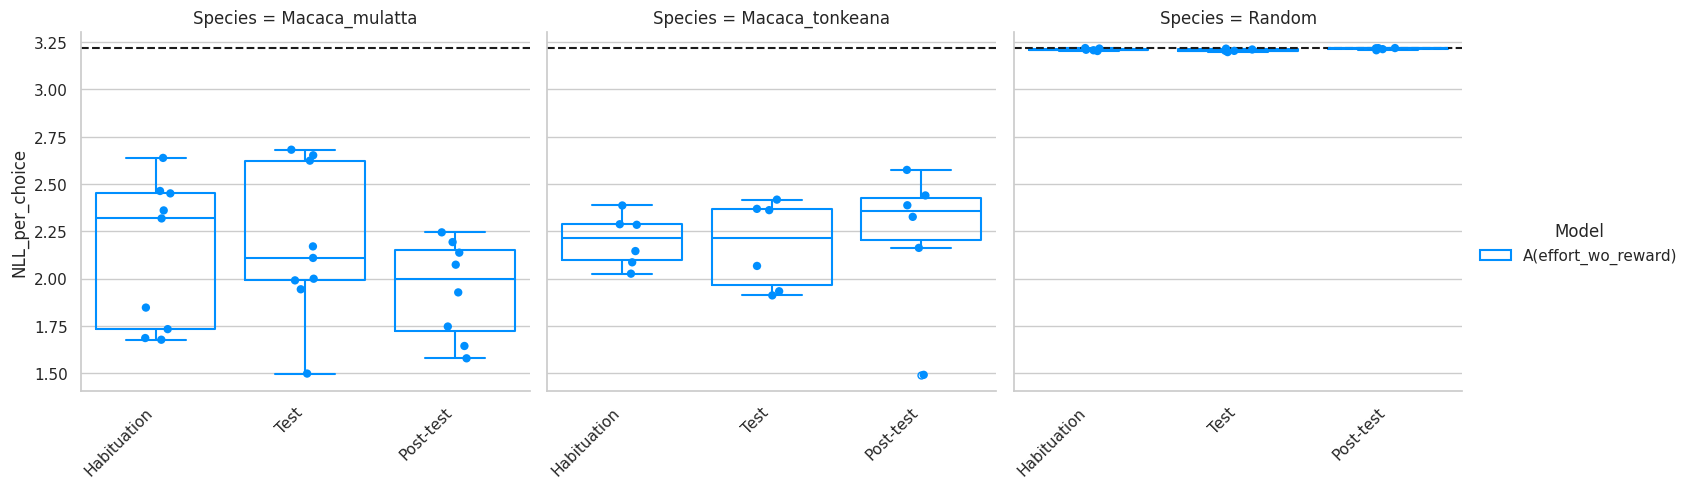

In [160]:
g1 = plot_boxplots_with_points("Phase","NLL_per_choice","Species","Model",phase_order,cmap5,best_model,3,True)

for ax in g1.axes:
    xlims = ax.get_xlim()
    ax.hlines(y=3.22,xmin=xlims[0],xmax=xlims[1],ls='dashed',color='k',lw=1.5)
    ax.set_xlim(xlims[0],xlims[1])
g1.savefig(fig_dir+"LL_with_respect_to_chance_level_high_res_space_updated_best_model.png")

In [161]:
compare_stats = pd.read_csv(data_dir+"all_model_stats.csv")
compare_trajs = pd.read_csv(data_dir+"all_model_trajs.csv")
compare_dist_trajs = pd.read_csv(data_dir+"all_model_dist_trajs.csv")

In [162]:
# compare_trajs = pd.DataFrame()
# compare_stats = pd.DataFrame()
# compare_dist_trajs = pd.DataFrame()
# compare_visit_map = pd.DataFrame()


# for grp in best_model.groupby(['Model', 'Subject', 'Phase', 'Species']):

#     model = grp[0][0]
#     Subject = grp[0][1]
#     Phase = grp[0][2]
#     Species = grp[0][3]

#     fit = grp[1].iloc[0]

#     # ------------------------------------------------------------
#     # Common fitted parameters
#     # ------------------------------------------------------------

#     if model == 'A' or model == 'A(effort)':
#         wRS = fit['WS(row)']
#         wCS = fit['WS(column)']
#         wSS_cw = fit['WS(cw_spiral)']
#         wSS_ccw = fit['WS(ccw_spiral)']
#         spatial_weights = [wRS, wCS, wSS_cw,wSS_ccw]
#     elif model == 'B' or model == 'B(effort)':
#         spatial_weights = []
#         for k in DIRECTIONS.keys():
#             spatial_weights.append(fit['WS('+k+')'])
#     elif model == 'C' or model == 'C(effort)':
#         spatial_weights = []
#         for k in MODEL_C_NAMES:
#             spatial_weights.append(fit['WS('+k+')'])
        
        

#     wK = fit['W(spatial_bias)']
#     wR = fit['W(reward)']
#     wM = fit['W(memory)']
#     if 'effort' in model:
#         wE = fit['W(effort)']

#     decay = fit['memory_recall']
#     beta = fit['beta']




#     # ------------------------------------------------------------
#     # Get actual trajectories
#     # ------------------------------------------------------------

#     sim_trajs = []

#     act_data = all_data.loc[
#         (all_data['Subject'] == Subject) &
#         (all_data['Phase'] == Phase) &
#         (all_data['Species'] == Species)
#     ].copy()

#     act_trajs = [
#         [[x, y] for x, y in zip(tr.Rows[:20], tr.Cols[:20])]
#         for _, tr in act_data.groupby('Session')
#     ]

#     Nsim = len(act_trajs)


#     # ------------------------------------------------------------
#     # Statistics containers
#     # ------------------------------------------------------------

#     stats_act = {
#         'revisit_rate': [],
#         'traj_num': [],
#         'jump_length': [],
#         'first_revisit': [],
#         'total_dist': []
#     }

#     stats_sim = {
#         'revisit_rate': [],
#         'traj_num': [],
#         'jump_length': [],
#         'first_revisit': [],
#         'total_dist': []
#     }


#     dist_between_trajs = []
#     corr_between_trajs = []
#     trials = []


#     # ------------------------------------------------------------
#     # Simulate trajectory-by-trajectory
#     # ------------------------------------------------------------

#     for i, traj in enumerate(act_trajs):

#         start = traj[0]
#         if 'effort' in model:
#             # Common arguments
#             sim_kwargs = dict(
#                 start_loc=start,
#                 T=len(traj) - 1,
#                 sigma=1.0,
#                 decay=decay,
#                 wK=wK,
#                 wR=wR,
#                 wM=wM,
#                 wE =wE,
#                 beta=beta,
#                 spatial_weights=spatial_weights,
#                 model=model.split('(effort')[0]
#             )
            
#             # New simulate_case()
#             sim_result = bmm_spat_with_effort.simulate_case(**sim_kwargs)
            
#         else:
#             # Common arguments
#             sim_kwargs = dict(
#                 start_loc=start,
#                 T=len(traj) - 1,
#                 sigma=1.0,
#                 decay=decay,
#                 wK=wK,
#                 wR=wR,
#                 wM=wM,
#                 beta=beta,
#                 spatial_weights=spatial_weights,
#                 model=model
#             )


#             # New simulate_case()
#             sim_result = bmm_spat_wo_effort.simulate_case(**sim_kwargs)

#         # First returned object is always the trajectory
#         sim = sim_result[0]

#         sim_trajs.append(sim)
#         trials.append([i] * len(traj))


#         # --------------------------------------------------------
#         # Behavioral statistics
#         # --------------------------------------------------------

#         revis_act = bmm_spat_wo_effort.revisit_rate(traj)
#         first_rev_act = bmm_spat_wo_effort.first_revisit(traj)
#         revis_sim = bmm_spat_wo_effort.revisit_rate(sim)
#         first_rev_sim = bmm_spat_wo_effort.first_revisit(sim)

#         mean_jump_act, var_jump_act, tot_jump_act = bmm_spat_wo_effort.jump_lengths(traj)

#         mean_jump_sim, var_jump_sim, tot_jump_sim = bmm_spat_wo_effort.jump_lengths(sim)

#         tot_dist_act = bmm_spat_wo_effort.calc_total_distance_covered(traj)
#         tot_dist_sim = bmm_spat_wo_effort.calc_total_distance_covered(sim)


#         # Actual
#         stats_act['revisit_rate'].append(revis_act)
#         stats_act['jump_length'].append(mean_jump_act)
#         stats_act['first_revisit'].append(first_rev_act)
#         stats_act['total_dist'].append(tot_dist_act)
#         stats_act['traj_num'].append(i)

#         # Model
#         stats_sim['revisit_rate'].append(revis_sim)
#         stats_sim['jump_length'].append(mean_jump_sim)
#         stats_sim['first_revisit'].append(first_rev_sim)
#         stats_sim['total_dist'].append(tot_dist_sim)
#         stats_sim['traj_num'].append(i)


#         # --------------------------------------------------------
#         # Distance between actual and simulated trajectory
#         # --------------------------------------------------------

#         dist, corr = bmm_spat_wo_effort.calc_dist_bw_traj(traj, sim)

#         dist_between_trajs.append(dist)
#         corr_between_trajs.append(corr)


#     # ------------------------------------------------------------
#     # Visit maps
#     # ------------------------------------------------------------

#     Vobs = sum(
#         bmm_spat_wo_effort.visit_map(t)
#         for t in act_trajs
#     )

#     Vsim = sum(
#         bmm_spat_wo_effort.visit_map(t)
#         for t in sim_trajs
#     )


#     Vobs_df = pd.DataFrame(
#         Vobs,
#         columns=np.arange(1, 6),
#         index=np.arange(1, 6)
#     )

#     Vobs_df['type'] = 'data'


#     Vsim_df = pd.DataFrame(
#         Vsim,
#         columns=np.arange(1, 6),
#         index=np.arange(1, 6)
#     )

#     Vsim_df['type'] = 'model - '+model


#     Vmap = pd.concat([
#         Vobs_df,
#         Vsim_df
#     ])

# #     Vmap['Model'] = model
#     Vmap['Subject'] = Subject
#     Vmap['Phase'] = Phase
#     Vmap['Species'] = Species


#     compare_visit_map = pd.concat([
#         compare_visit_map,
#         Vmap
#     ])


#     # ------------------------------------------------------------
#     # Behavioral statistics dataframe
#     # ------------------------------------------------------------

#     stats_act_df = pd.DataFrame(stats_act)
#     stats_act_df['type'] = 'data'

#     stats_sim_df = pd.DataFrame(stats_sim)
#     stats_sim_df['type'] = 'model - '+model

#     to_add = pd.concat([
#         stats_act_df,
#         stats_sim_df
#     ])

# #     to_add['Model'] = model
#     to_add['Subject'] = Subject
#     to_add['Phase'] = Phase
#     to_add['Species'] = Species


#     compare_stats = pd.concat([
#         compare_stats,
#         to_add
#     ])


#     # ------------------------------------------------------------
#     # Distance between trajectories
#     # ------------------------------------------------------------

#     temp_df = pd.DataFrame()

#     temp_df['dist_traj(model,data)'] = dist_between_trajs
#     temp_df['corr_traj(model,data)'] = corr_between_trajs

#     temp_df['Model'] = model
#     temp_df['Subject'] = Subject
#     temp_df['Phase'] = Phase
#     temp_df['Species'] = Species


#     compare_dist_trajs = pd.concat([
#         compare_dist_trajs,
#         temp_df
#     ])


#     # ------------------------------------------------------------
#     # Actual vs simulated trajectories
#     # ------------------------------------------------------------

#     temp = pd.DataFrame()

#     temp['Rows_model'] = np.hstack([np.array(x)[:,0] for x in sim_trajs])  #np.array(sim_trajs)[:, :, 0].flatten()
#     temp['Cols_model'] = np.hstack([np.array(x)[:,1] for x in sim_trajs]) #np.array(sim_trajs)[:, :, 1].flatten()

#     temp['Rows_data'] = np.hstack([np.array(x)[:,0] for x in act_trajs])#np.array(act_trajs)[:, :, 0].flatten()
#     temp['Cols_data'] = np.hstack([np.array(x)[:,1] for x in act_trajs])#np.array(act_trajs)[:, :, 1].flatten()

#     temp['Trials'] = np.hstack(trials)

#     temp['Model'] = model
#     temp['Subject'] = Subject
#     temp['Phase'] = Phase
#     temp['Species'] = Species


#     compare_trajs = pd.concat([
#         compare_trajs,
#         temp
#     ])


In [163]:
compare_stats

,Unnamed: 0,revisit_rate,traj_num,jump_length,first_revisit,total_dist,type,Subject,Phase,Species
0,0,0.00,0,1.631579,0,25.883627,data,Amidala,Habituation,Macaca_mulatta
1,1,0.10,1,1.894737,14,29.963990,data,Amidala,Habituation,Macaca_mulatta
2,2,0.05,2,2.000000,15,31.896819,data,Amidala,Habituation,Macaca_mulatta
3,3,0.10,3,2.105263,7,34.712101,data,Amidala,Habituation,Macaca_mulatta
4,4,0.05,4,1.947368,19,31.491901,data,Amidala,Habituation,Macaca_mulatta
...,...,...,...,...,...,...,...,...,...,...
7933,5,0.25,5,2.157895,6,33.829602,model - C(effort_wo_reward),Yin,Test,Macaca_tonkeana
7934,6,0.25,6,1.842105,5,30.698909,model - C(effort_wo_reward),Yin,Test,Macaca_tonkeana
7935,7,0.10,7,2.263158,11,34.059097,model - C(effort_wo_reward),Yin,Test,Macaca_tonkeana
7936,8,0.20,8,1.684211,6,28.423669,model - C(effort_wo_reward),Yin,Test,Macaca_tonkeana


In [164]:
best_model_stats = compare_stats.loc[compare_stats['type'].isin(['model - A(effort_wo_reward)','data'])].copy()
stats_melt = best_model_stats.melt(id_vars=['Subject','Species','Phase','type','traj_num','Unnamed: 0'])

In [165]:
sns.set(style='whitegrid',font_scale=1.5)


<Figure size 640x480 with 0 Axes>

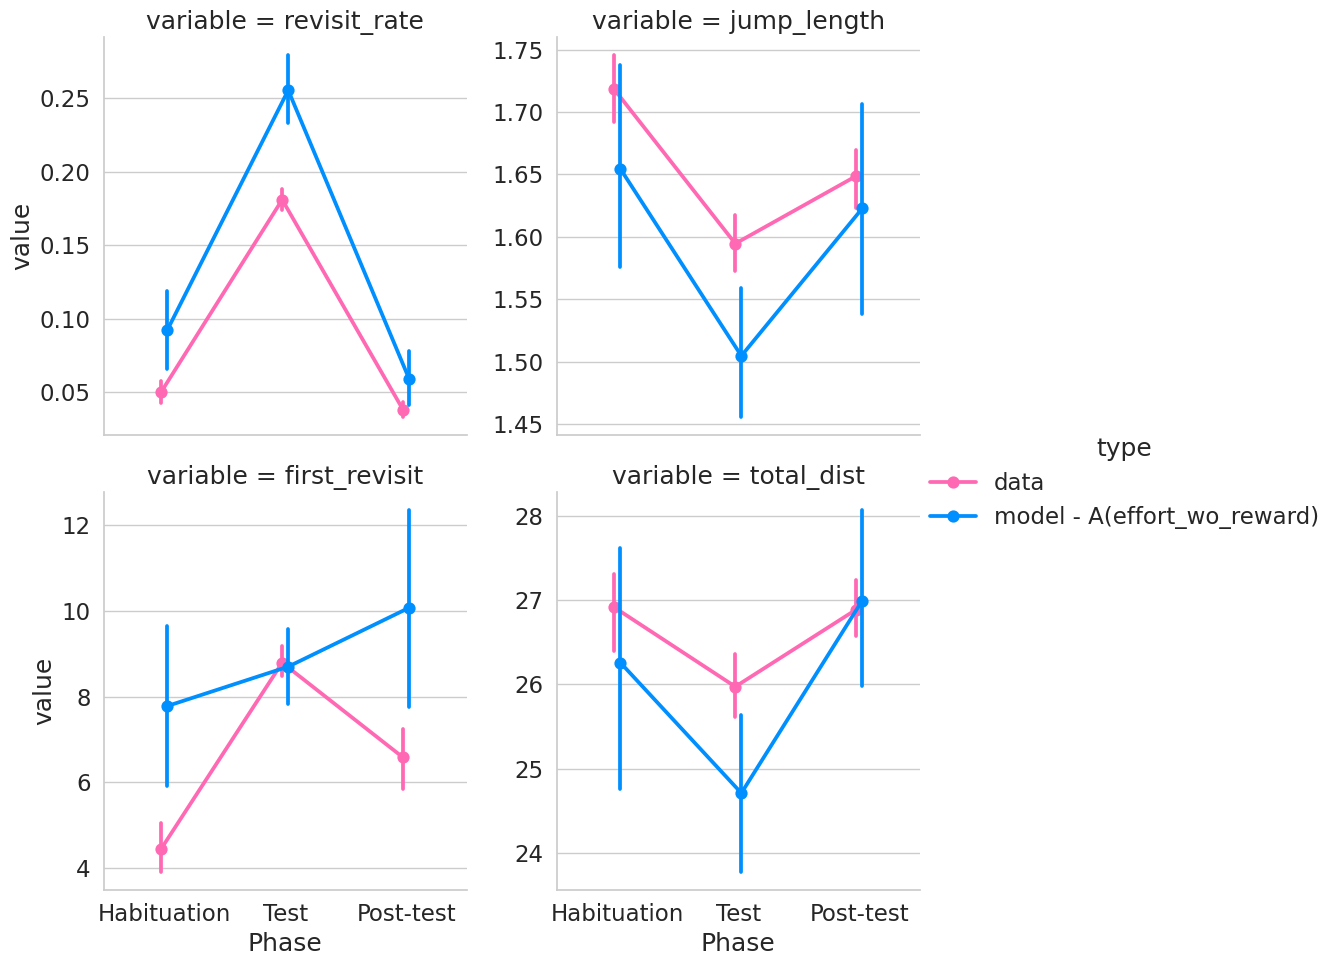

<Figure size 640x480 with 0 Axes>

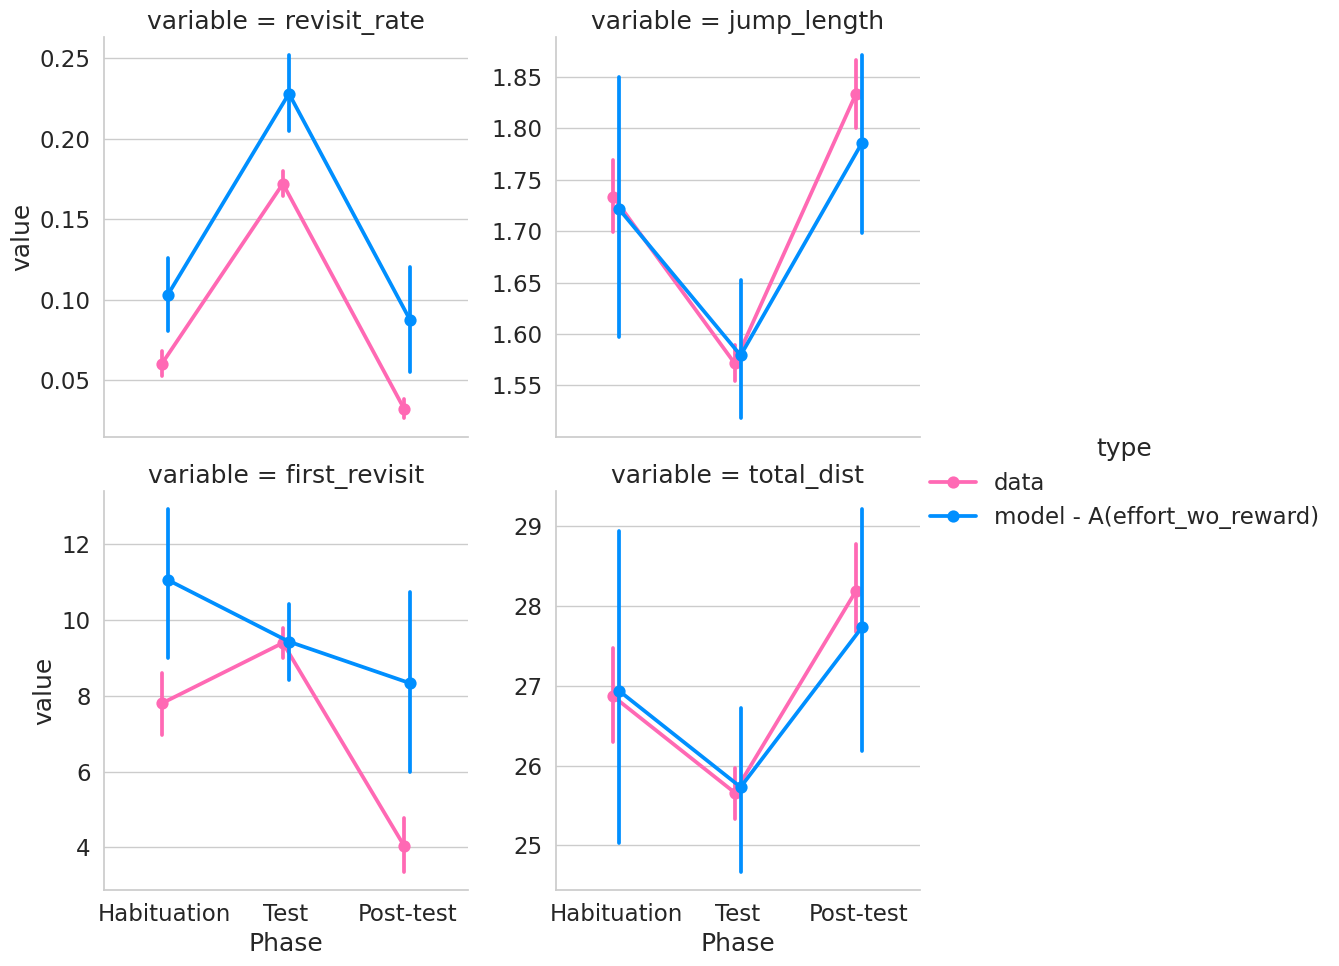

<Figure size 640x480 with 0 Axes>

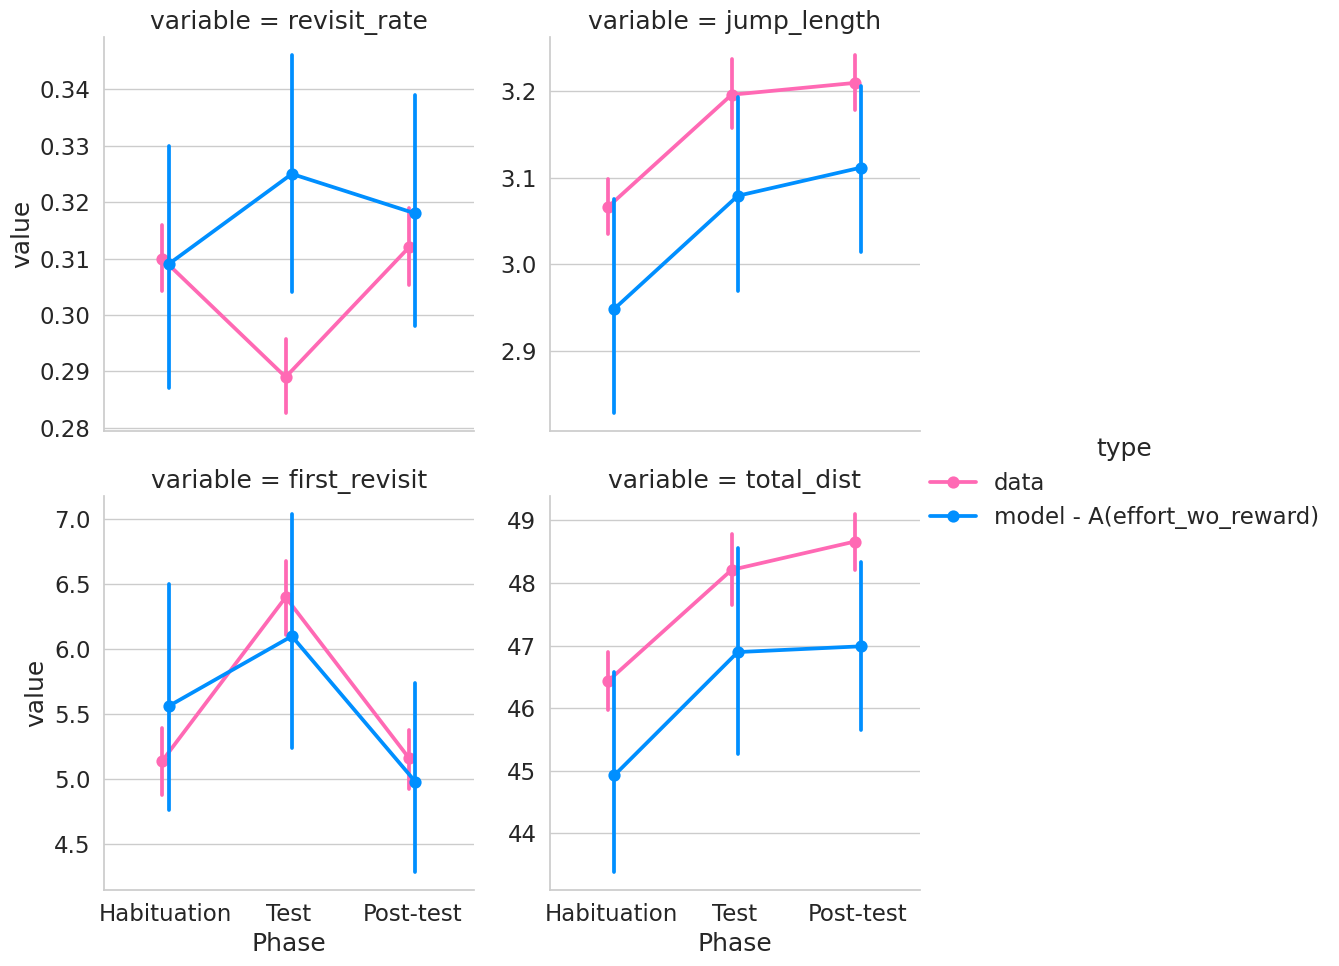

In [166]:
for grp in stats_melt.groupby('Species'):
    pl.figure()
    g1 = sns.catplot(x="Phase",y='value',hue='type',kind='point',col='variable',col_wrap=2,data=grp[1],palette=cmap4,sharey=False,order=phase_order,dodge=True)
    g1.savefig(fig_dir+"stats_compare_data_model_"+grp[0]+"_model_comparison_"+"high_res_updated_best_model.png")

In [167]:
to_plot = best_model.melt(id_vars=['Subject','Species','Phase','NLL_per_choice','Model','BIC','NLL','Random_NLL_per_choice','nchoices','success'])

to_plot = to_plot.loc[~to_plot['variable'].str.contains('Unnamed')].dropna()
to_plot

,Subject,Species,Phase,NLL_per_choice,Model,BIC,NLL,Random_NLL_per_choice,nchoices,success,variable,value
0,Amidala,Macaca_mulatta,Habituation,2.318325,A(effort_wo_reward),481.466678,220.240893,3.218876,95,True,WS(row),0.000128
1,Amidala,Macaca_mulatta,Post-test,1.927347,A(effort_wo_reward),407.180764,183.097936,3.218876,95,True,WS(row),0.503215
2,Amidala,Macaca_mulatta,Test,2.109500,A(effort_wo_reward),848.833082,400.804933,3.218876,190,True,WS(row),0.222912
3,Anyanka,Macaca_mulatta,Habituation,1.685988,A(effort_wo_reward),361.322563,160.168835,3.218876,95,True,WS(row),0.406239
4,Anyanka,Macaca_mulatta,Post-test,1.578890,A(effort_wo_reward),340.973901,149.994505,3.218876,95,True,WS(row),0.316407
...,...,...,...,...,...,...,...,...,...,...,...,...
1175,Yannick,Macaca_tonkeana,Post-test,1.491574,A(effort_wo_reward),324.383991,141.699550,3.218876,95,True,W(effort),5.312692
1176,Yannick,Macaca_tonkeana,Test,1.911460,A(effort_wo_reward),773.577961,363.177372,3.218876,190,True,W(effort),9.211721
1177,Yin,Macaca_tonkeana,Habituation,2.386774,A(effort_wo_reward),494.471958,226.743533,3.218876,95,True,W(effort),7.614975
1178,Yin,Macaca_tonkeana,Post-test,2.387871,A(effort_wo_reward),475.190206,217.296235,3.218876,91,True,W(effort),9.085569


In [168]:
to_plot.loc[to_plot['variable']=='W(reward)']

,Subject,Species,Phase,NLL_per_choice,Model,BIC,NLL,Random_NLL_per_choice,nchoices,success,variable,value


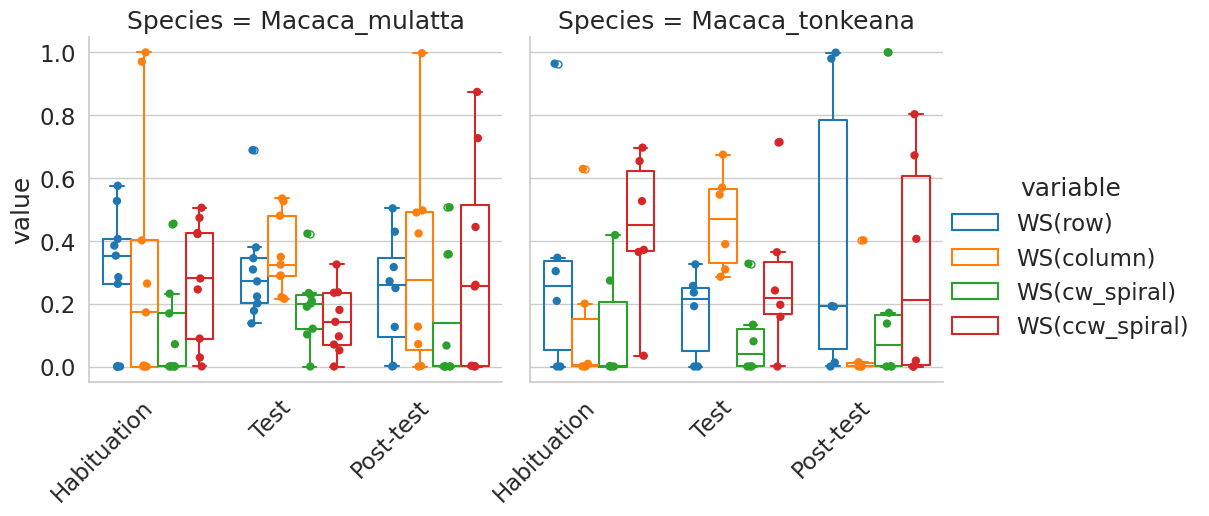

In [169]:
weights_spatial_df = to_plot.loc[to_plot['variable'].str.contains('WS')].copy()
weights_other_df = to_plot.loc[(to_plot['variable'].str.contains('W')&~(to_plot['variable'].str.contains('WS')))].copy()

for grp in weights_spatial_df.groupby('Model'):
    g1_sp_wt = plot_boxplots_with_points("Phase","value","Species",'variable',phase_order,cmap2,grp[1].loc[grp[1]['Species']!='Random'].dropna(),2,True,True)
    g1_sp_wt.savefig(fig_dir+"comparison_weights_with_points_spatial_mix_"+grp[0]+"high_res_updated_best_model.png")    

A(effort_wo_reward)


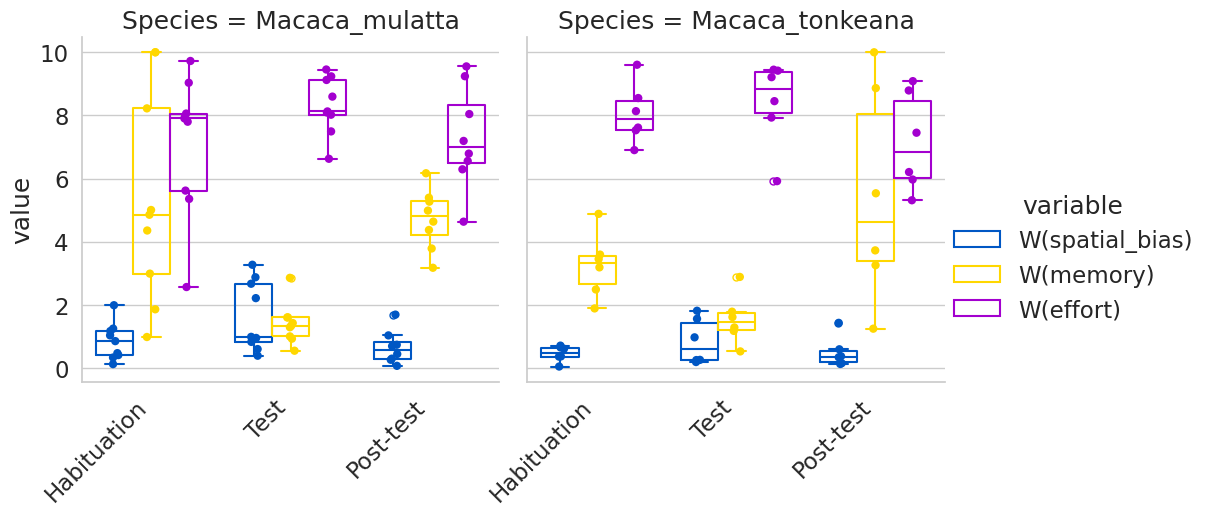

In [170]:
# for grp in weights_other_df.groupby('Species'): 
print(grp[0])
g1_oth_wt = plot_boxplots_with_points("Phase","value",'Species','variable',phase_order,'prism',weights_other_df.loc[weights_other_df['Species']!='Random'],2,True,True)
g1_oth_wt.savefig(fig_dir+"comparison_weights_with_points_other_"+"high_res_updated_best_model.png")    

In [171]:
weights_other_df

,Subject,Species,Phase,NLL_per_choice,Model,BIC,NLL,Random_NLL_per_choice,nchoices,success,variable,value
236,Amidala,Macaca_mulatta,Habituation,2.318325,A(effort_wo_reward),481.466678,220.240893,3.218876,95,True,W(spatial_bias),0.122588
237,Amidala,Macaca_mulatta,Post-test,1.927347,A(effort_wo_reward),407.180764,183.097936,3.218876,95,True,W(spatial_bias),0.443018
238,Amidala,Macaca_mulatta,Test,2.109500,A(effort_wo_reward),848.833082,400.804933,3.218876,190,True,W(spatial_bias),0.950626
239,Anyanka,Macaca_mulatta,Habituation,1.685988,A(effort_wo_reward),361.322563,160.168835,3.218876,95,True,W(spatial_bias),0.330027
240,Anyanka,Macaca_mulatta,Post-test,1.578890,A(effort_wo_reward),340.973901,149.994505,3.218876,95,True,W(spatial_bias),0.693116
...,...,...,...,...,...,...,...,...,...,...,...,...
1175,Yannick,Macaca_tonkeana,Post-test,1.491574,A(effort_wo_reward),324.383991,141.699550,3.218876,95,True,W(effort),5.312692
1176,Yannick,Macaca_tonkeana,Test,1.911460,A(effort_wo_reward),773.577961,363.177372,3.218876,190,True,W(effort),9.211721
1177,Yin,Macaca_tonkeana,Habituation,2.386774,A(effort_wo_reward),494.471958,226.743533,3.218876,95,True,W(effort),7.614975
1178,Yin,Macaca_tonkeana,Post-test,2.387871,A(effort_wo_reward),475.190206,217.296235,3.218876,91,True,W(effort),9.085569


In [172]:
# g1 = sns.relplot(x='W(effort)',y='W(reward)',data=best_model.loc[best_model['Species']!='Random'],hue='Species',col='Phase',kind='scatter',s=50,marker='P',facet_kws={'sharex':False,'sharey':False})

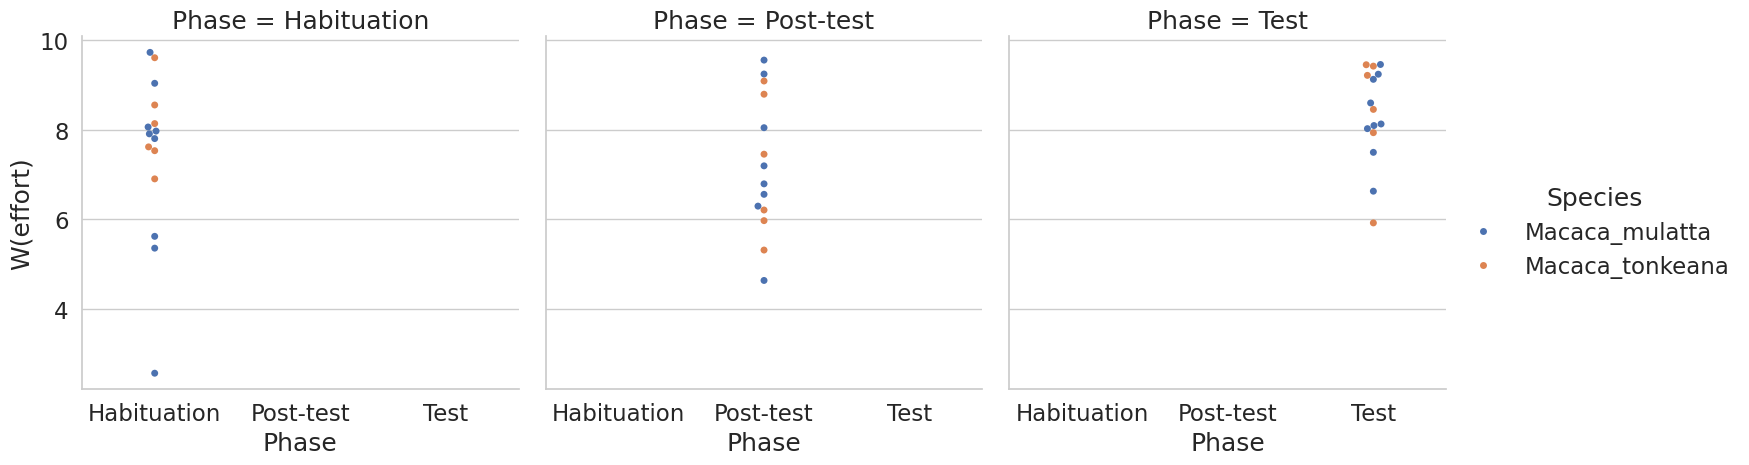

In [173]:
g1 = sns.catplot(x='Phase',y='W(effort)',hue='Species',col='Phase',data=best_model.loc[best_model['Species']!='Random'],kind='swarm')

In [145]:
other_pars = to_plot.loc[~(to_plot['variable'].str.contains('W')|(to_plot['variable'].str.contains('nchoices')))]
other_pars

,Subject,Species,Phase,NLL_per_choice,Model,BIC,NLL,Random_NLL_per_choice,nchoices,success,variable,value
413,Amidala,Macaca_mulatta,Habituation,2.318325,A(effort_wo_reward),481.466678,220.240893,3.218876,95,True,memory_recall,0.931483
414,Amidala,Macaca_mulatta,Post-test,1.927347,A(effort_wo_reward),407.180764,183.097936,3.218876,95,True,memory_recall,0.947444
415,Amidala,Macaca_mulatta,Test,2.109500,A(effort_wo_reward),848.833082,400.804933,3.218876,190,True,memory_recall,0.696533
416,Anyanka,Macaca_mulatta,Habituation,1.685988,A(effort_wo_reward),361.322563,160.168835,3.218876,95,True,memory_recall,0.988497
417,Anyanka,Macaca_mulatta,Post-test,1.578890,A(effort_wo_reward),340.973901,149.994505,3.218876,95,True,memory_recall,0.934701
...,...,...,...,...,...,...,...,...,...,...,...,...
526,Yannick,Macaca_tonkeana,Post-test,1.491574,A(effort_wo_reward),324.383991,141.699550,3.218876,95,True,beta,20.000000
527,Yannick,Macaca_tonkeana,Test,1.911460,A(effort_wo_reward),773.577961,363.177372,3.218876,190,True,beta,8.747014
528,Yin,Macaca_tonkeana,Habituation,2.386774,A(effort_wo_reward),494.471958,226.743533,3.218876,95,True,beta,9.113220
529,Yin,Macaca_tonkeana,Post-test,2.387871,A(effort_wo_reward),475.190206,217.296235,3.218876,91,True,beta,8.331908


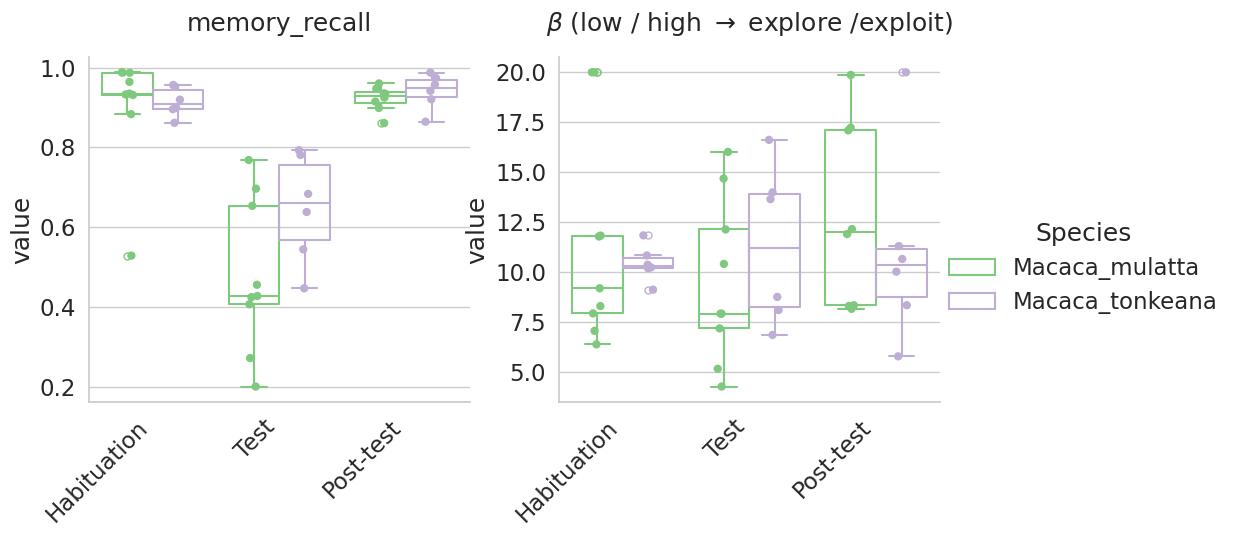

In [146]:
g1_oth = plot_boxplots_with_points("Phase","value","variable",'Species',phase_order,'Accent',other_pars.loc[other_pars['Species']!='Random'],2,True,False)
for ax in g1_oth.axes:
    tit = ax.get_title().split(' = ')[1]
    if tit == 'beta':
        tit = r'$\beta$'+' (low / high '+r'$\rightarrow$'+' explore /exploit)'
    ax.set_title(tit,y=1.05)
    ax.set_xlabel("")
g1_oth.savefig(fig_dir+"comparison_other_params_with_points_model_comparison_"+"high_res_updated_best_model.png")    


In [48]:
recovery_df = pd.read_csv(data_dir+"recovery_reward_models_A_effort.csv")
recovery_df

,Model,Subject,Phase,Species,iter,LL,WS(row),WS(row) - sim,WS(column),WS(column) - sim,...,W(reward),W(reward) - sim,W(memory),W(memory) - sim,W(effort,W(effort - sim,memory_recall,memory_recall - sim,beta,beta - sim
0,A(effort),Amidala,Habituation,Macaca_mulatta,0,299.276796,0.477415,0.571135,0.520866,0.421852,...,1.239936,2.881625,6.588615,6.784577,9.374837,NaN,0.928799,0.964717,6.300311,5.636585
1,A(effort),Amidala,Habituation,Macaca_mulatta,1,316.073126,0.477415,0.255092,0.520866,0.557853,...,1.239936,0.726483,6.588615,7.423721,9.374837,NaN,0.928799,0.923669,6.300311,5.627452
2,A(effort),Amidala,Habituation,Macaca_mulatta,2,290.364959,0.477415,0.404405,0.520866,0.595537,...,1.239936,2.134969,6.588615,6.807194,9.374837,NaN,0.928799,0.917256,6.300311,6.431196
3,A(effort),Amidala,Habituation,Macaca_mulatta,3,299.347521,0.477415,0.309171,0.520866,0.568357,...,1.239936,0.967213,6.588615,6.808888,9.374837,NaN,0.928799,0.948936,6.300311,6.725138
4,A(effort),Amidala,Habituation,Macaca_mulatta,4,310.617446,0.477415,0.426805,0.520866,0.573012,...,1.239936,3.177684,6.588615,9.107943,9.374837,NaN,0.928799,0.943954,6.300311,4.530657
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
435,A(effort),Yin,Test,Macaca_tonkeana,5,1499.095577,0.257520,0.228935,0.547164,0.635485,...,0.010000,0.010000,2.111331,1.636689,10.000000,NaN,0.543202,0.508755,5.765843,7.876654
436,A(effort),Yin,Test,Macaca_tonkeana,6,1517.934906,0.257520,0.311558,0.547164,0.463794,...,0.010000,0.358833,2.111331,2.123509,10.000000,NaN,0.543202,0.536832,5.765843,5.469517
437,A(effort),Yin,Test,Macaca_tonkeana,7,1529.378831,0.257520,0.253567,0.547164,0.512157,...,0.010000,0.182144,2.111331,2.366079,10.000000,NaN,0.543202,0.612188,5.765843,5.495218
438,A(effort),Yin,Test,Macaca_tonkeana,8,1452.664899,0.257520,0.265054,0.547164,0.582605,...,0.010000,0.010000,2.111331,2.322276,10.000000,NaN,0.543202,0.603834,5.765843,6.354138


In [54]:
recovery_df.columns

Index(['Model', 'Subject', 'Phase', 'Species', 'iter', 'LL', 'WS(row)',
       'WS(row) - sim', 'WS(column)', 'WS(column) - sim', 'WS(cw_spiral)',
       'WS(cw_spiral) - sim', 'WS(ccw_spiral)', 'WS(ccw_spiral) - sim',
       'W(spatial_bias)', 'W(spatial_bias) - sim', 'W(reward)',
       'W(reward) - sim', 'W(memory)', 'W(memory) - sim', 'W(effort',
       'W(effort - sim', 'memory_recall', 'memory_recall - sim', 'beta',
       'beta - sim'],
      dtype='object')

In [52]:
base_params = [
    "WS(row)", "WS(column)", "WS(cw_spiral)","WS(ccw_spiral)",
    "W(spatial_bias)", "W(reward)", "W(memory)","W(effort",
    "memory_recall", "beta",
]

/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/matplotlib/axes/_axes.py:1185: RuntimeWarning: All-NaN axis encountered
  miny = np.nanmin(masked_verts[..., 1])
/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/matplotlib/axes/_axes.py:1186: RuntimeWarning: All-NaN axis encountered
  maxy = np.nanmax(masked_verts[..., 1])
/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/matplotlib/axes/_axes.py:1185: RuntimeWarning: All-NaN axis encountered
  miny = np.nanmin(masked_verts[..., 1])
/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/matplotlib/axes/_axes.py:1186: RuntimeWarning: All-NaN axis encountered
  maxy = np.nanmax(masked_verts[..., 1])
/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/matplotlib/axes/_axes.py:1185: RuntimeWarning: All-NaN axis encountered
  miny = np.nanmin(masked_verts[..., 1])
/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/matplotli

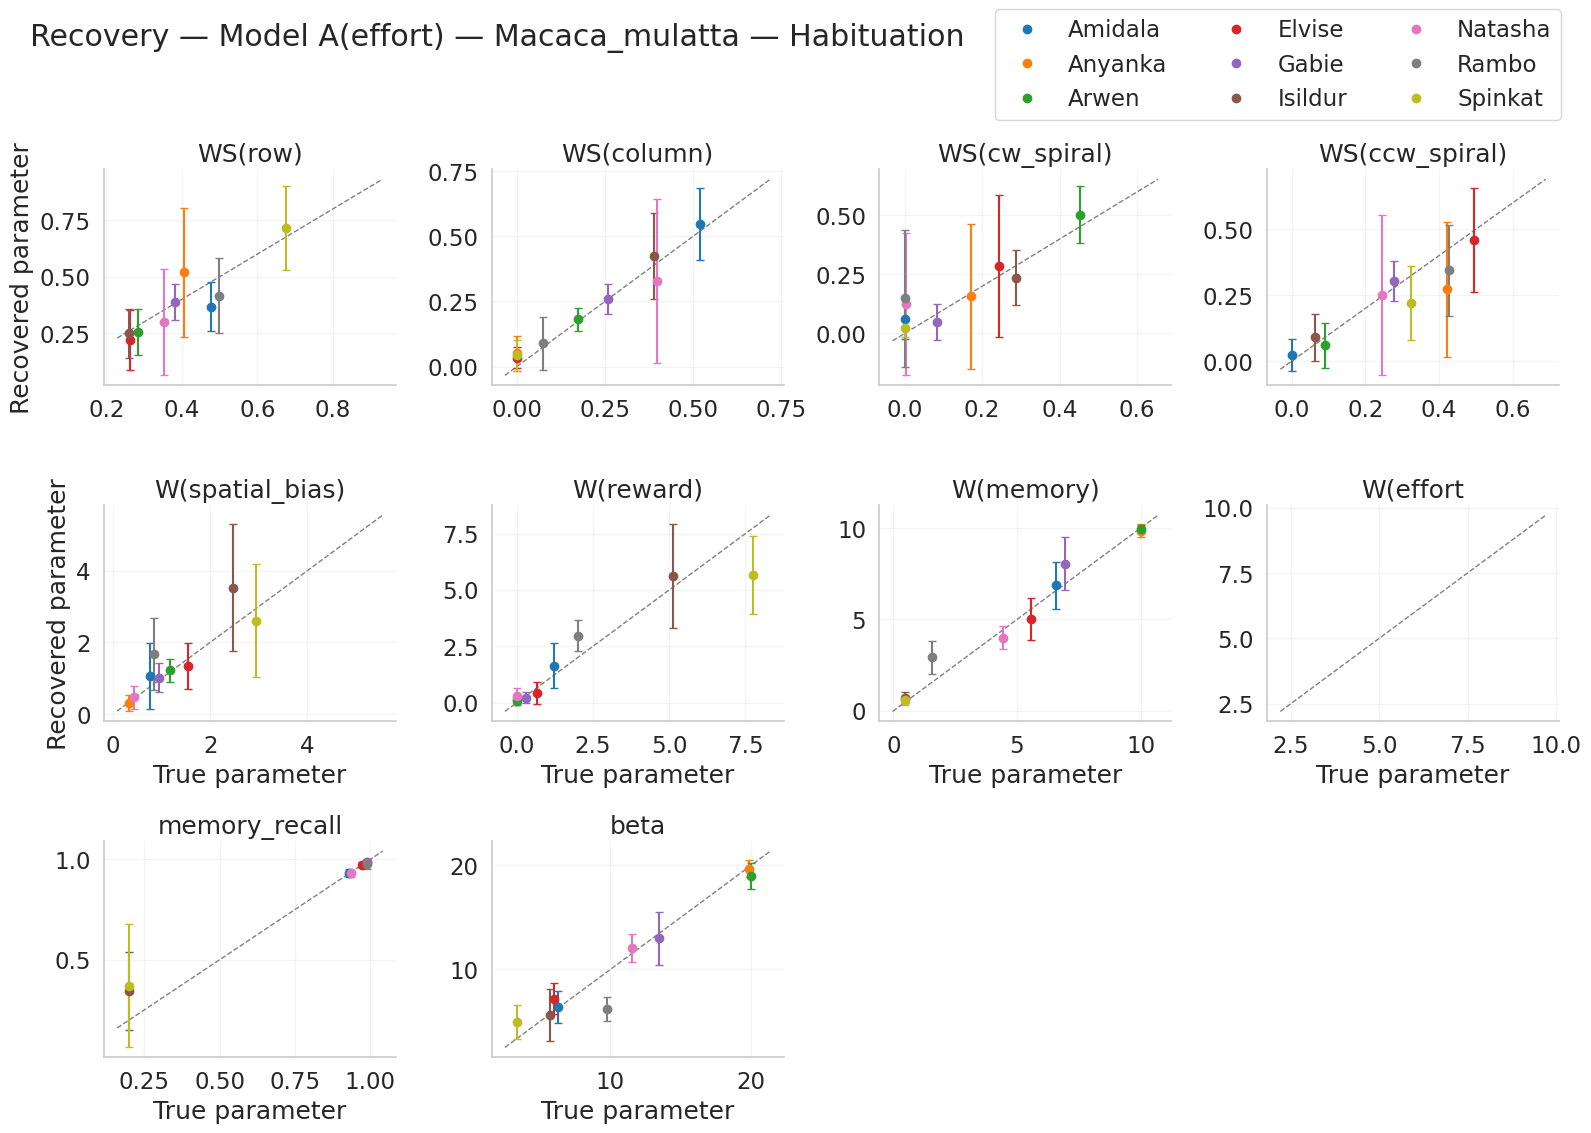

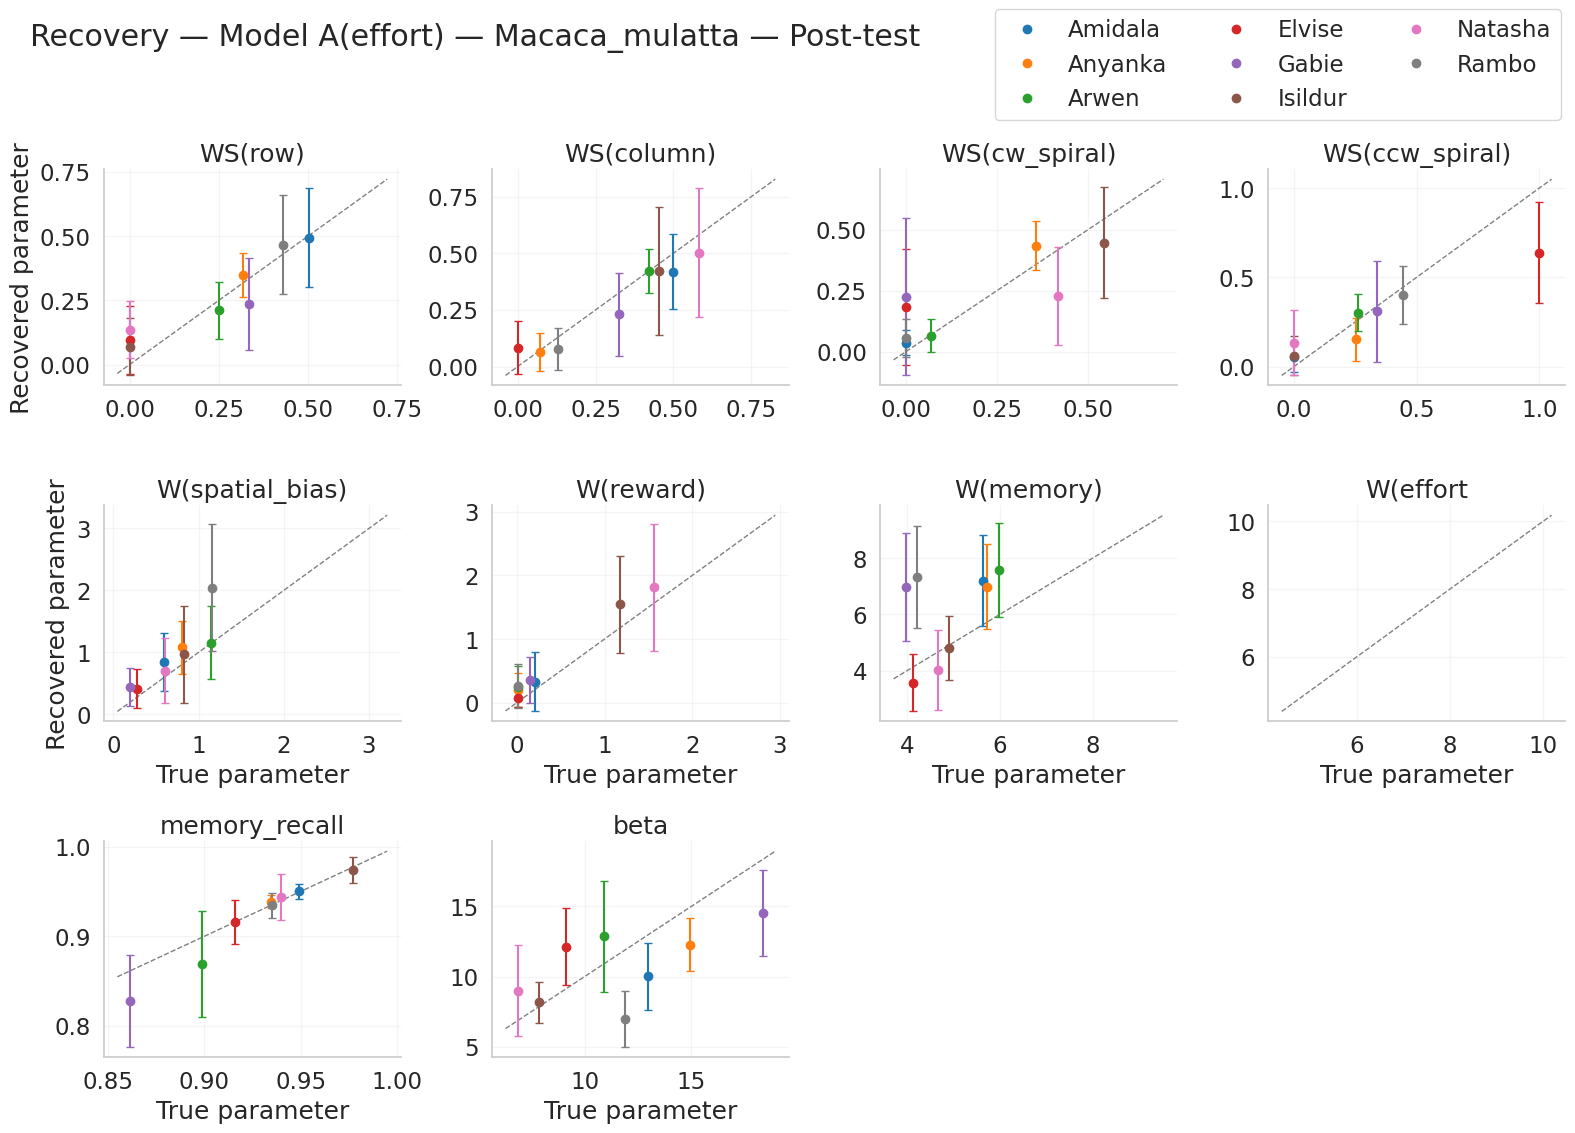

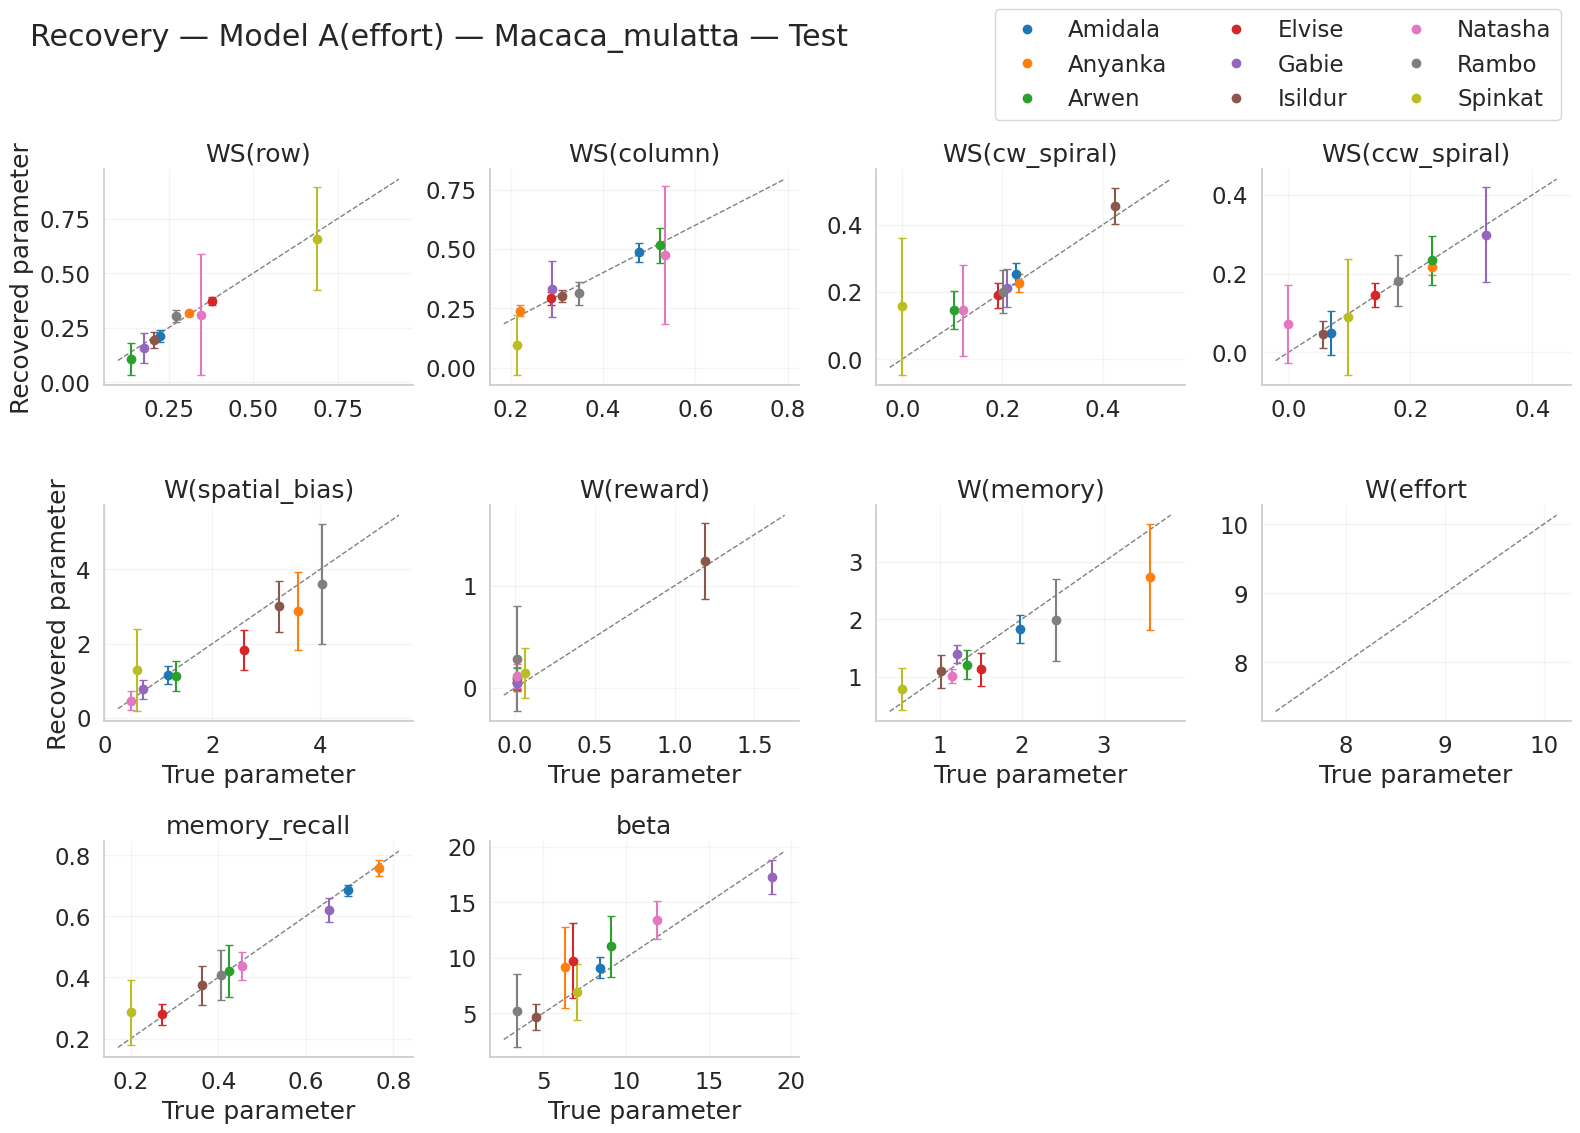

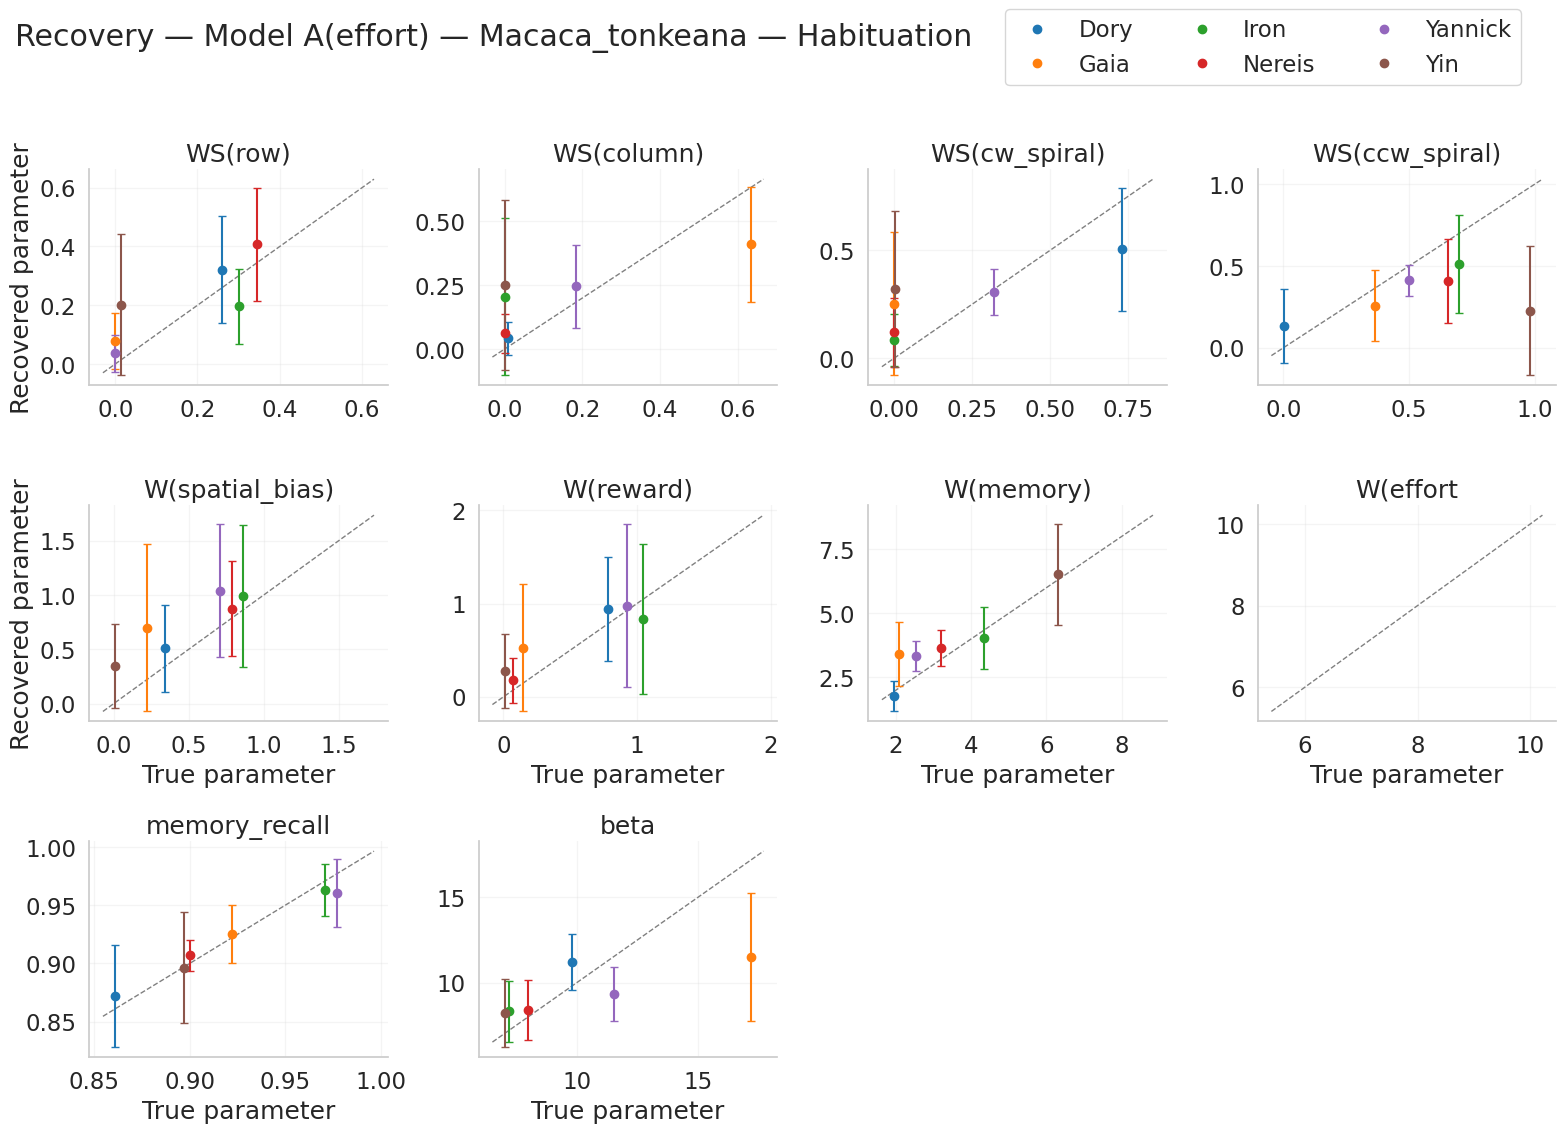

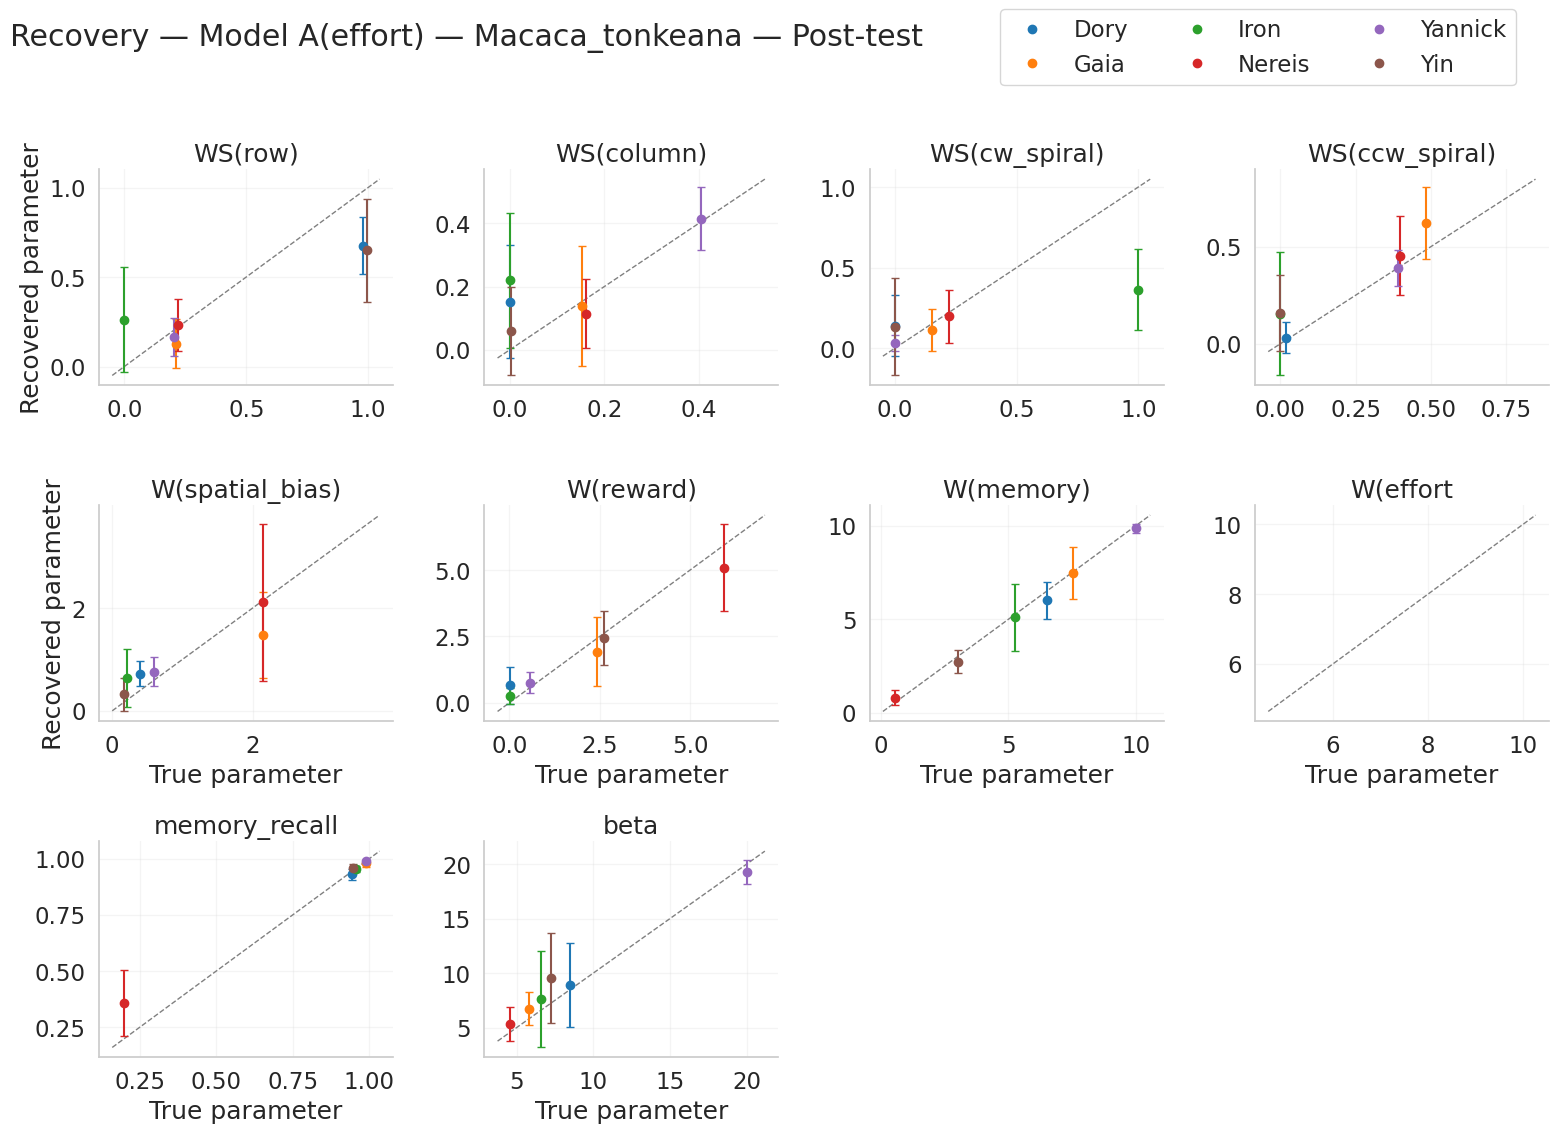

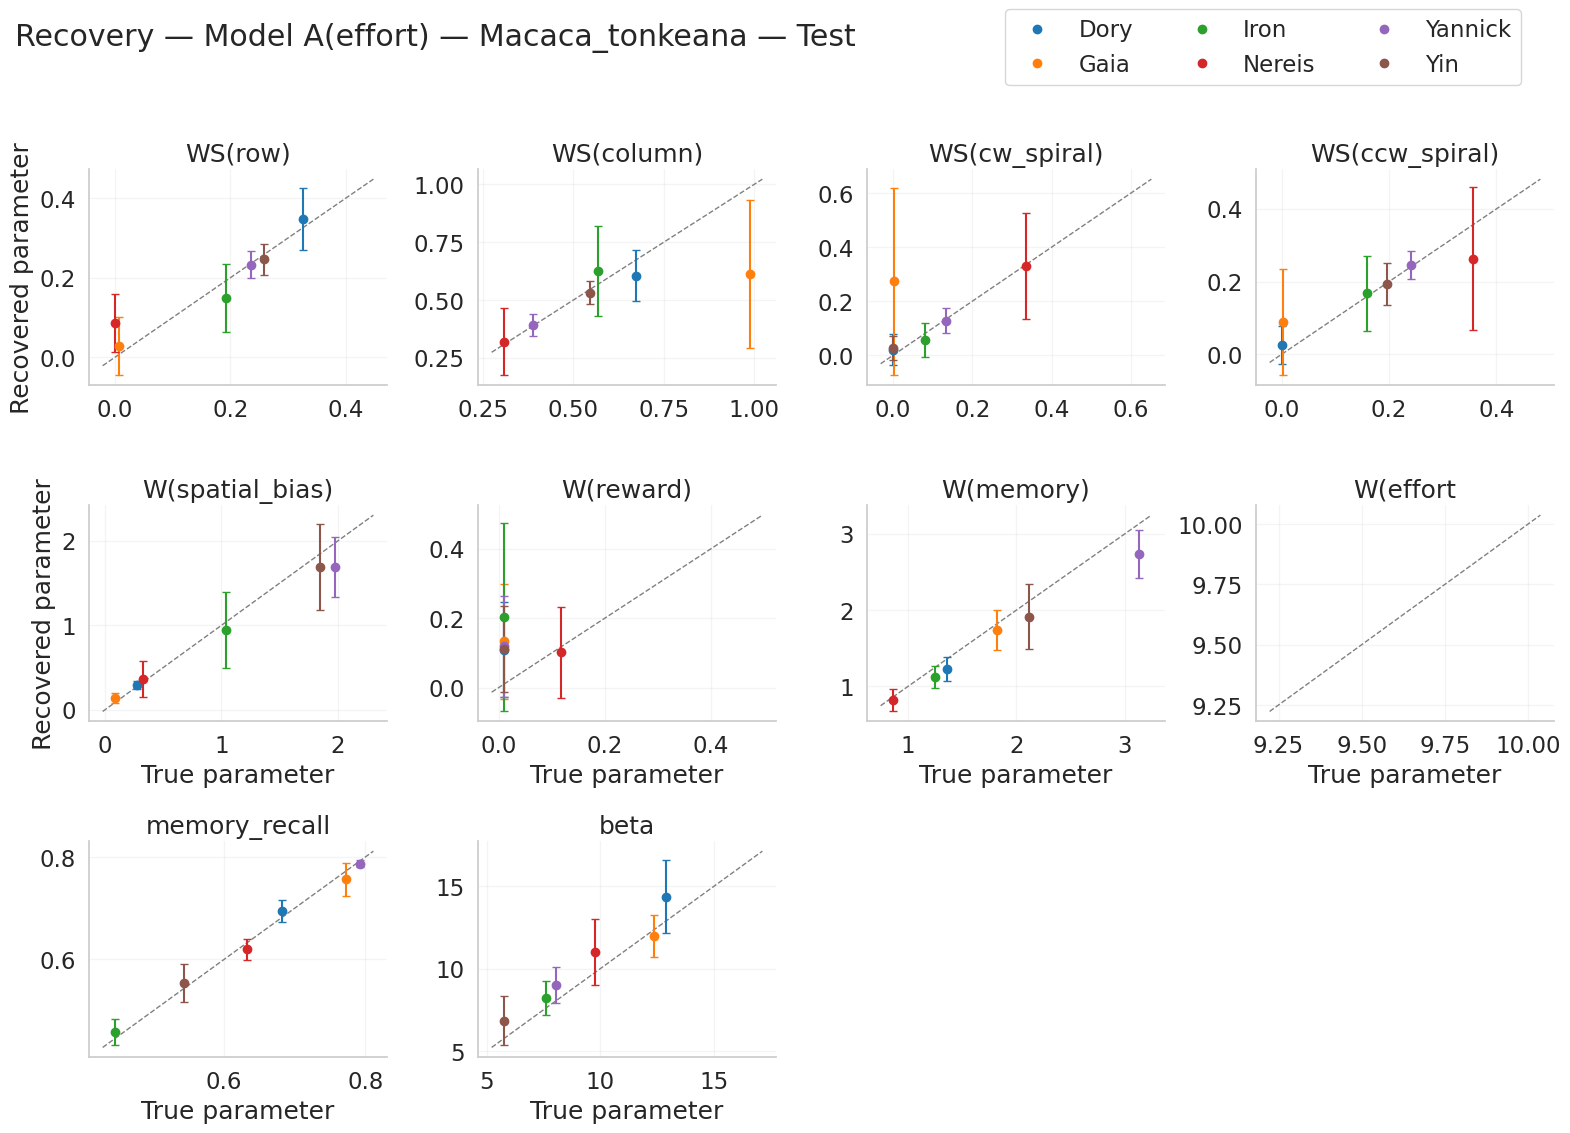

In [55]:
model_params = {
    "A(effort)": base_params,
#     "B": base_params + ["reward_decay"],
#     "C": base_params + ["W(reward_availability)"],
}

# plt.rcParams['axes.titley'] = 0.97
# plt.rcParams['axes.titlelocation'] = 'left' 

for model in ["A(effort)"]:#, "B"]:
    submodel = recovery_df[recovery_df["Model"] == model].copy()

    for species in sorted(submodel["Species"].dropna().unique()):
        for phase in sorted(
            submodel.loc[submodel["Species"] == species, "Phase"]
            .dropna().unique()
        ):
            sub = submodel[
                (submodel["Species"] == species)
                & (submodel["Phase"] == phase)
            ].copy()

            params = [
                p for p in model_params[model]
                if p in sub.columns and f"{p} - sim" in sub.columns
            ]

            ncols = 4
            nrows = int(np.ceil(len(params) / ncols))
            fig, axes = plt.subplots(
                nrows, ncols, figsize=(16, 4*nrows), squeeze=False
            )
            axes = axes.flatten()

            subjects = sorted(sub["Subject"].dropna().unique())
            cmap = plt.get_cmap("tab10")
            subject_colors = {
                s: cmap(i % 10) for i, s in enumerate(subjects)
            }
            
            ax_i = 0
            for ax, par in zip(axes, params):
                rec = f"{par} - sim"
                summary = (
                    sub.groupby("Subject")
                    .agg(
                        true_value=(par, "first"),
                        recovered_mean=(rec, "mean"),
                        recovered_sd=(rec, "std"),
                    )
                    .reset_index()
                )

                valid = pd.concat([
                    summary["true_value"],
                    summary["recovered_mean"] + summary["recovered_sd"]
                ]).dropna()

                if len(valid):
                    lo, hi = valid.min(), valid.max()
                    pad = 0.05 if np.isclose(lo, hi) else 0.05*(hi-lo)
                    if np.isclose(lo, hi) and lo != 0:
                        pad = abs(lo)*0.05
                    ax.plot(
                        [lo-pad, hi+pad], [lo-pad, hi+pad],
                        "--", color="gray", linewidth=1
                    )

                for _, row in summary.iterrows():
                    if pd.isna(row["true_value"]):
                        continue
                    ax.errorbar(
                        row["true_value"],
                        row["recovered_mean"],
                        yerr=row["recovered_sd"],
                        fmt="o", markersize=6, capsize=3,
                        color=subject_colors[row["Subject"]]
                    )

                ax.set_xlabel("True parameter")
                ax.set_ylabel("Recovered parameter")
                ax.set_title(par)
                ax.grid(alpha=0.2)
                if ax_i <=3 :
                    ax.set_xlabel("")

                if ax_i not in [0,4]:
                    ax.set_ylabel("")

                ax.spines.top.set_visible(False)
                ax.spines.right.set_visible(False)
                ax_i = ax_i + 1                

            for ax in axes[len(params):]:
                ax.axis("off")

            handles = [
                Line2D(
                    [0], [0], marker="o", linestyle="",
                    color=subject_colors[s], label=s, markersize=6
                )
                for s in subjects
            ]
            if handles:
#                 if 'tonkean' in species and model == 'A':
                    
                if 'mulatta' in species and model == 'B' :
                    fig.legend(
                        handles=handles, loc="lower center",
                        ncol=min(3, len(handles)),
                        bbox_to_anchor=(0.5, 0.2)
                    )
                else:
                    fig.legend(
                        handles=handles, loc="upper center",
                        ncol=min(3, len(handles)),
                        bbox_to_anchor=(0.8, 1.0)
                    )
                    
                    
            fig.suptitle(
                f"Recovery — Model {model} — {species} — {phase}",x=0.02,y=0.98,ha="left",va="top"             
            )
            plt.tight_layout(rect=[0, 0.04, 1, 0.95])
            fig.savefig(fig_dir+"recovery_plots_"+model+"_"+species+"_"+phase+".png")            

/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/matplotlib/axes/_axes.py:1185: RuntimeWarning: All-NaN axis encountered
  miny = np.nanmin(masked_verts[..., 1])
/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/matplotlib/axes/_axes.py:1186: RuntimeWarning: All-NaN axis encountered
  maxy = np.nanmax(masked_verts[..., 1])
/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/matplotlib/axes/_axes.py:1185: RuntimeWarning: All-NaN axis encountered
  miny = np.nanmin(masked_verts[..., 1])
/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/matplotlib/axes/_axes.py:1186: RuntimeWarning: All-NaN axis encountered
  maxy = np.nanmax(masked_verts[..., 1])


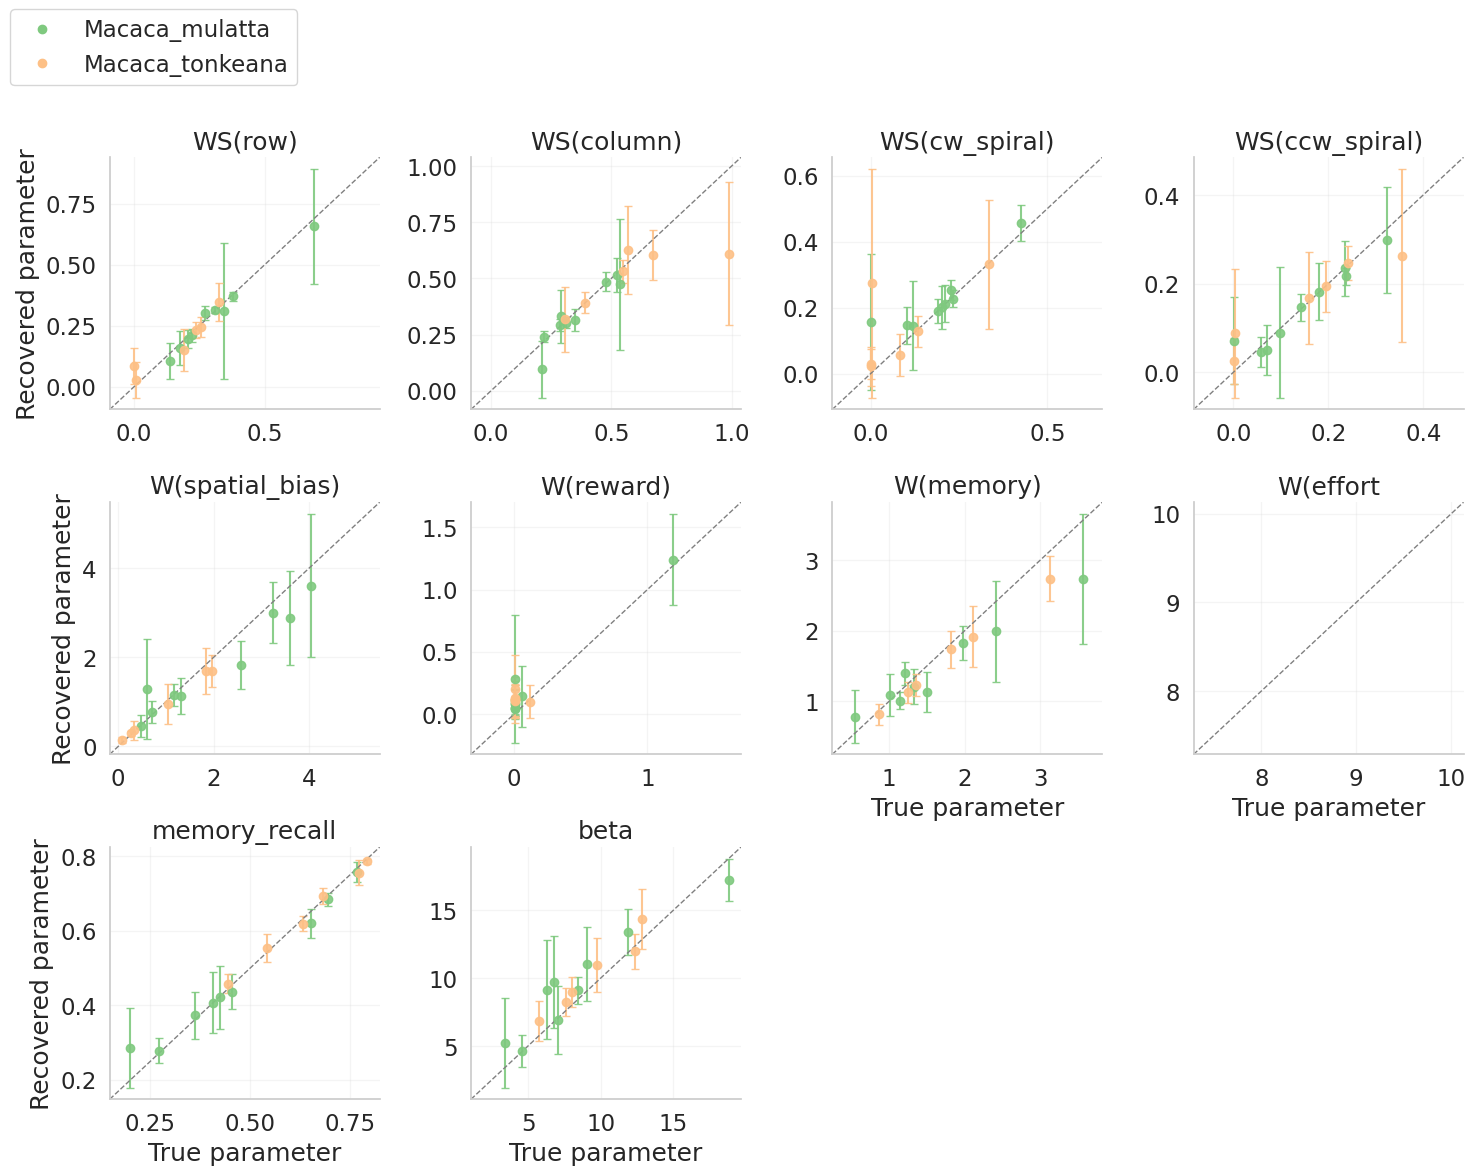

In [57]:
species_colors = {
    "Macaca_mulatta": colors_acc[0],
    "Macaca_tonkeana": colors_acc[1]
}

for model in ["A(effort)"]:  # , "B", "C"

    submodel = recovery_df[
        (recovery_df["Model"] == model) &
        (recovery_df["Phase"] == "Test")
    ].copy()

    # Parameters for this model
    params = [
        p for p in model_params[model]
        if p in submodel.columns and f"{p} - sim" in submodel.columns
    ]

    # One subplot per parameter
    ncols = 4
    nrows = int(np.ceil(len(params) / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(16, 4 * nrows),
        squeeze=False
    )
    axes = axes.flatten()

    # ---------------------------------------------------------
    # Plot each parameter
    # ---------------------------------------------------------
    for ax_i, (ax, par) in enumerate(zip(axes, params)):

        rec = f"{par} - sim"

        all_summary = []

        # Plot both species on the same axis
        for species in sorted(species_colors.keys()):

            sub = submodel[
                submodel["Species"] == species
            ].copy()

            if sub.empty:
                continue

            summary = (
                sub.groupby("Subject")
                .agg(
                    true_value=(par, "first"),
                    recovered_mean=(rec, "mean"),
                    recovered_sd=(rec, "std"),
                )
                .reset_index()
            )

            summary["Species"] = species
            all_summary.append(summary)

            # ---------------------------------------------
            # Plot recovery points for this species
            # ---------------------------------------------
            for _, row in summary.iterrows():

                if pd.isna(row["true_value"]):
                    continue

                ax.errorbar(
                    row["true_value"],
                    row["recovered_mean"],
                    yerr=row["recovered_sd"],
                    fmt="o",
                    markersize=6,
                    capsize=3,
                    color=species_colors[species],
                    alpha=0.9
                )

        # -----------------------------------------------------
        # Identity line using BOTH species' parameter ranges
        # -----------------------------------------------------
        if all_summary:

            combined = pd.concat(all_summary, ignore_index=True)

            valid = pd.concat([
                combined["true_value"],
                combined["recovered_mean"] + combined["recovered_sd"],
                combined["recovered_mean"] - combined["recovered_sd"]
            ]).dropna()

            if len(valid):

                lo = valid.min()
                hi = valid.max()

                if np.isclose(lo, hi):
                    pad = abs(lo) * 0.05 if lo != 0 else 0.05
                else:
                    pad = 0.05 * (hi - lo)

                lo -= pad
                hi += pad

                ax.plot(
                    [lo, hi],
                    [lo, hi],
                    "--",
                    color="gray",
                    linewidth=1
                )

                ax.set_xlim(lo, hi)
                ax.set_ylim(lo, hi)

        # -----------------------------------------------------
        # Formatting
        # -----------------------------------------------------
        ax.set_title(par)
        ax.grid(alpha=0.2)

        # Only bottom row gets x-label
        if ax_i < len(params) - ncols:
            ax.set_xlabel("")
        else:
            ax.set_xlabel("True parameter")

        # Only first column gets y-label
        if ax_i % ncols == 0:
            ax.set_ylabel("Recovered parameter")
        else:
            ax.set_ylabel("")

        ax.spines.top.set_visible(False)
        ax.spines.right.set_visible(False)

    # ---------------------------------------------------------
    # Hide unused axes
    # ---------------------------------------------------------
    for ax in axes[len(params):]:
        ax.axis("off")

    # ---------------------------------------------------------
    # Species legend
    # ---------------------------------------------------------
    handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=species_colors[s],
            label=s,
            markersize=6
        )
        for s in sorted(species_colors.keys())
        if s in submodel["Species"].unique()
    ]

    fig.legend(
        handles=handles,
        loc="upper right",
        bbox_to_anchor=(0.2, 0.995),
        ncol=1
    )

    # ---------------------------------------------------------
    # Title
    # ---------------------------------------------------------
    fig.suptitle("",
#         f"Recovery — Model {model} — Test",
        x=0.02,
        y=0.98,
        ha="left",
        va="top"
    )

    plt.tight_layout(
        rect=[0, 0, 0.94, 0.93]
    )

#     plt.show()
    fig.savefig(fig_dir+'Recovery_plots_Test_both_species.png',dpi=300)

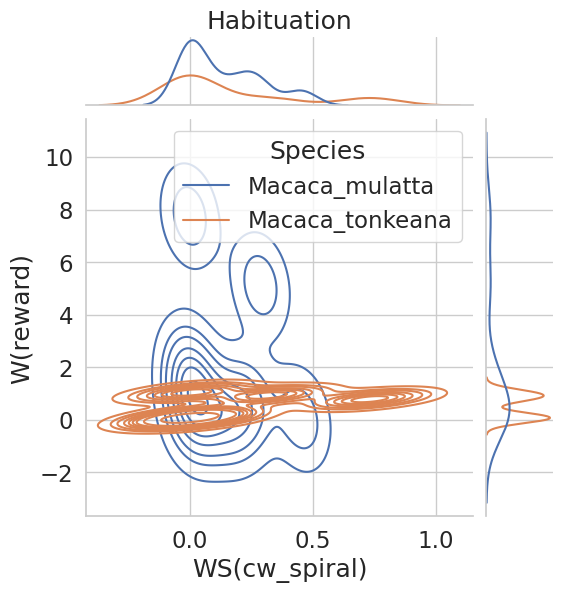

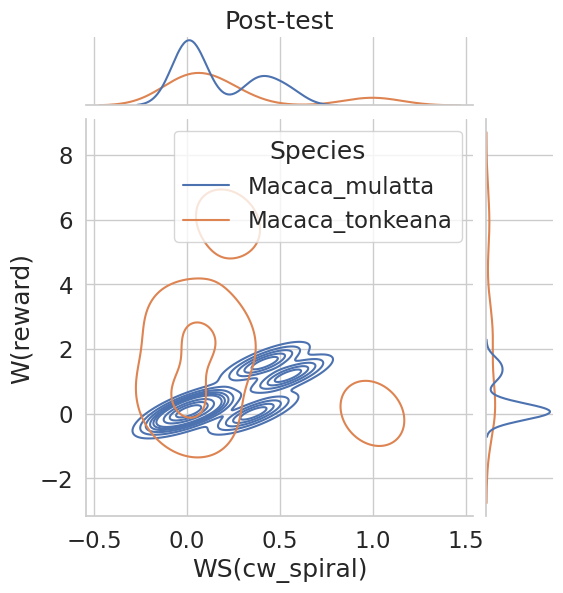

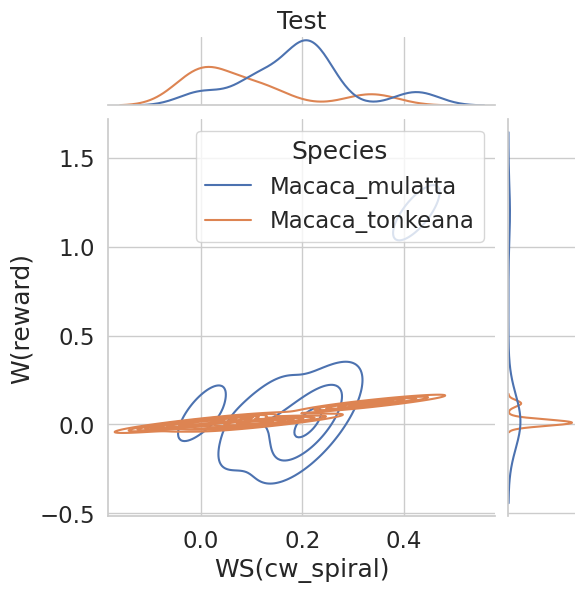

In [68]:
for grp in recovery_df.groupby('Phase'):
    g1 = sns.jointplot(x="WS(cw_spiral)",y="W(reward)",data=grp[1],kind='kde',hue='Species')
    g1.ax_marg_x.set_title(grp[0])
    

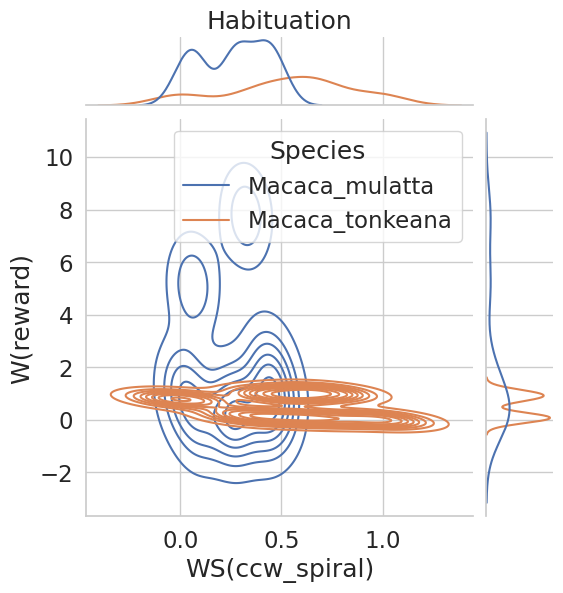

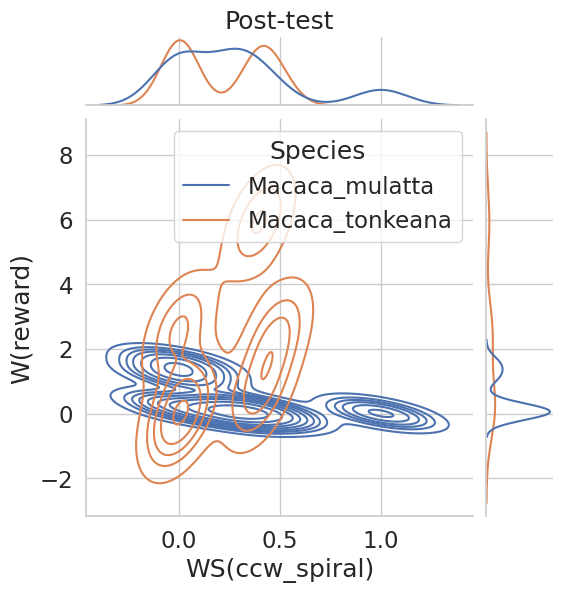

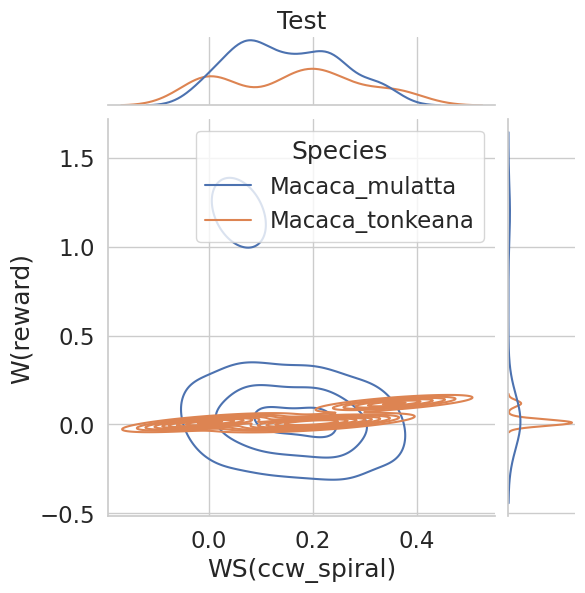

In [69]:
for grp in recovery_df.groupby('Phase'):
    g1 = sns.jointplot(x="WS(ccw_spiral)",y="W(reward)",data=grp[1],kind='kde',hue='Species')
    g1.ax_marg_x.set_title(grp[0])
    

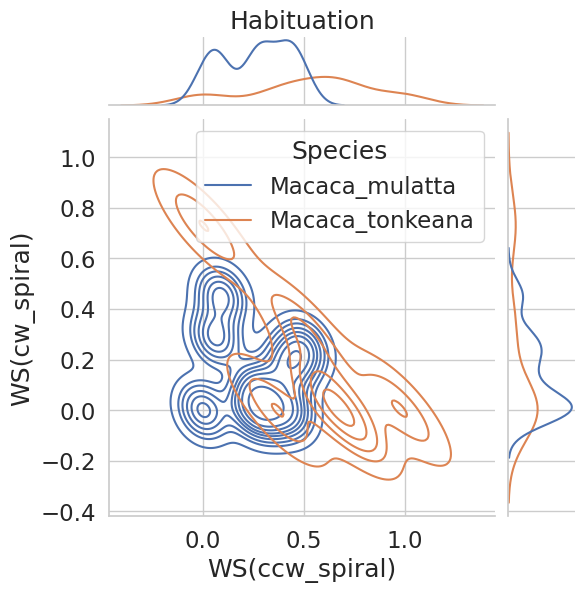

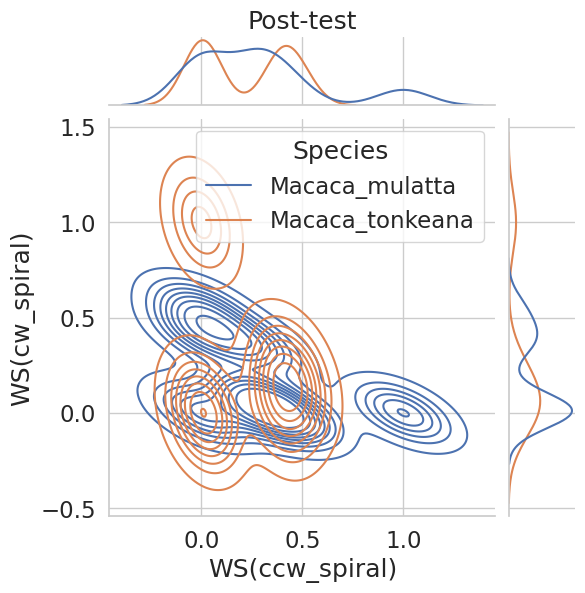

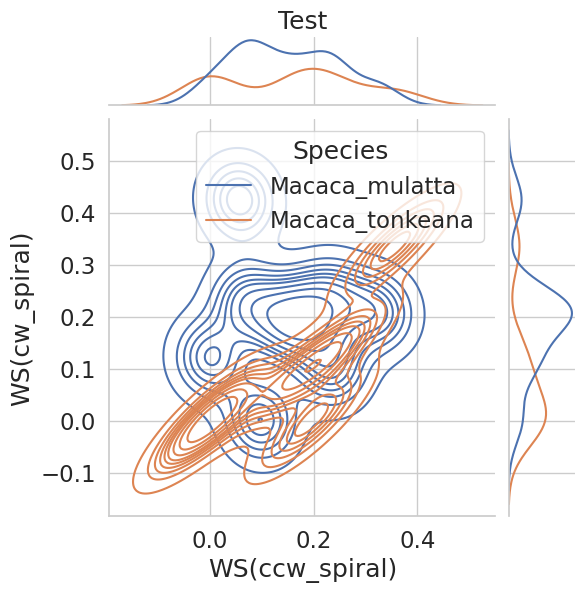

In [70]:
for grp in recovery_df.groupby('Phase'):
    g1 = sns.jointplot(x="WS(ccw_spiral)",y="WS(cw_spiral)",data=grp[1],kind='kde',hue='Species')
    g1.ax_marg_x.set_title(grp[0])